# Segmentation d’images de microscopie cellulaire

## 1. Imports

In [11]:
import os, gc, io, random, zipfile, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage as ndi
from skimage.morphology import dilation, disk
from skimage.transform import resize

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, jaccard_score, precision_recall_curve,
    roc_auc_score, average_precision_score
)
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

try:  # Colab : monte Google Drive (sans effet ailleurs)
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

SEED = 42
RANDOM_STATE = SEED
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow :", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

def cleanup_memory(objs=None):
    """Libère la mémoire GPU et RAM entre deux modèles."""
    if objs:
        for o in objs:
            del o
    keras.backend.clear_session()
    gc.collect()

TensorFlow : 2.10.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
# Nettoyage mémoire pour sauvegarder de la RAM
cleanup_memory()

## 2. Données

### 2.1 Chargement des données

In [51]:
DATA_DIR = Path("./data")

# Dataset 1
DATA_ZIP_PATH = DATA_DIR / "PhC-C2DH-U373_train.zip"
# Dataset 2
# DATA_ZIP_PATH = DATA_DIR / "DIC-C2DH-HeLa_train.zip"

# Dimensions et paddings
IMG_SIZE = 388       # Sortie cible (388 x 388)
PAD_ORIG = 92        # 388 + 2*92 = 572 (architectures à entrée 572x572)
PAD_MULT16 = 94      # 388 + 2*94 = 576 (architectures multiples de 16/32)
MAX_SHIFT = 16       # Amplitude de translation aléatoire

# Carte de poids spatiale (Ronneberger et al., 2015)
W0, SIGMA = 10.0, 5.0

# Hyperparamètres communs DL
BATCH_SIZE = 4
LEARNING_RATE = 1e-4
EPOCHS = 20
PATIENCE = 8


def read_tif(source, is_mask=False):
    """Lit et redimensionne une image [0, 1] ou un masque d'instances entiers en (388, 388)."""
    arr = np.array(Image.open(source), dtype=np.int32 if is_mask else np.float32)
    if arr.ndim == 3:
        arr = arr[..., 0]
    if not is_mask:
        if arr.max() > 1.0:
            arr = arr / 255.0 if arr.max() <= 255.0 else (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)
        return resize(arr, (IMG_SIZE, IMG_SIZE), order=1, preserve_range=True, anti_aliasing=True).astype(np.float32)
    return resize(arr, (IMG_SIZE, IMG_SIZE), order=0, preserve_range=True, anti_aliasing=False).astype(np.int32)


def separate_touching_instances(inst):
    """Crée une frontière de fond (0) entre les cellules adjacentes à partir des labels d'instances."""
    fg = (inst > 0).astype(np.uint8)
    uids = [u for u in np.unique(inst) if u > 0]
    if len(uids) < 2:
        return fg
    overlap = sum(dilation(inst == u, disk(1)).astype(np.int32) for u in uids)
    fg[overlap >= 2] = 0
    return fg


def compute_weight_map(inst, binary_mask):
    """Calcule la carte de poids w(x) de Ronneberger et al. (2015) pour renforcer les bordures inter-cellulaires."""
    fg_ratio = float(np.mean(binary_mask > 0))
    w_c = np.where(binary_mask > 0, 1.0 / (fg_ratio + 1e-6), 1.0 / (1.0 - fg_ratio + 1e-6))
    w_c /= np.mean(w_c)

    uids = [u for u in np.unique(inst) if u > 0]
    if len(uids) < 2:
        return w_c.astype(np.float32)

    dists = np.sort(np.stack([ndi.distance_transform_edt(inst != u) for u in uids], axis=0), axis=0)
    w_border = W0 * np.exp(-((dists[0] + dists[1]) ** 2) / (2.0 * SIGMA ** 2))
    return (w_c + np.where(binary_mask == 0, w_border, 0.0)).astype(np.float32)

In [52]:
def load_pairs_from_zip(zip_path, sequences=("01", "02")):
    """Charge directement les paires (image, masque d'instance Silver Truth, seq_id) depuis l'archive ZIP."""
    pairs = []
    with zipfile.ZipFile(zip_path, "r") as zf:
        names = [n.replace("\\", "/") for n in zf.namelist() if not n.endswith("/") and "__MACOSX" not in n]
        for seq in sequences:
            segs = sorted(n for n in names if f"/{seq}_ST/SEG/" in f"/{n}" and Path(n).name.startswith("man_seg") and n.endswith(".tif"))
            imgs = {Path(n).name: n for n in names if len(Path(n).parts) >= 2 and Path(n).parts[-2] == seq and n.endswith(".tif")}
            for seg_path in segs:
                fid = Path(seg_path).stem.replace("man_seg", "")
                img_name = f"t{fid}.tif"
                if img_name in imgs:
                    img = read_tif(io.BytesIO(zf.read(imgs[img_name])), is_mask=False)
                    inst = read_tif(io.BytesIO(zf.read(seg_path)), is_mask=True)
                    pairs.append((img, inst, seq))
    if not pairs:
        raise FileNotFoundError(f"Aucune paire trouvée dans {zip_path}")
    return pairs


# Chargement et découpage stratifié : 64% Train / 16% Val / 20% Test
all_pairs = load_pairs_from_zip(DATA_ZIP_PATH)
seq_labels = [p[2] for p in all_pairs]

train_val_pairs, test_pairs, tv_labels, _ = train_test_split(
    all_pairs, seq_labels, test_size=0.20, random_state=SEED, stratify=seq_labels
)
train_pairs, val_pairs = train_test_split(
    train_val_pairs, test_size=0.20, random_state=SEED, stratify=tv_labels
)

print(f"Total : {len(all_pairs)} | Train : {len(train_pairs)} | Val : {len(val_pairs)} | Test : {len(test_pairs)}")

Total : 230 | Train : 147 | Val : 37 | Test : 46


### 2.2 Prétraitement des données

In [53]:
def prepare_split(pairs, mean=None, std=None):
    """Standardise (z-score) et génère les cibles d'entraînement (mask_sep, weight) et d'évaluation (mask_raw)."""
    if mean is None or std is None:
        raw_stack = np.stack([p[0] for p in pairs], axis=0)
        mean, std = float(raw_stack.mean()), float(raw_stack.std() + 1e-8)

    items = []
    for img, inst, _ in pairs:
        img_std = ((img - mean) / std).astype(np.float32)
        mask_raw = (inst > 0).astype(np.uint8)       # Référence stricte pour Val / Test
        mask_sep = separate_touching_instances(inst) # Cible d'entraînement avec bordures séparées
        w_map = compute_weight_map(inst, mask_sep)

        items.append({
            "img": img_std,
            "img_pad92": np.pad(img_std, PAD_ORIG, mode="reflect"),   # (572, 572)
            "img_pad94": np.pad(img_std, PAD_MULT16, mode="reflect"), # (576, 576)
            "mask_p": np.pad(mask_sep, PAD_ORIG, mode="reflect"),     # (572, 572) pour augmentation
            "w_p": np.pad(w_map, PAD_ORIG, mode="reflect"),           # (572, 572) pour augmentation
            "mask_raw": mask_raw,
            "weight": w_map,
        })
    return items, mean, std

Z-score Train -> mean=0.3246, std=0.0321


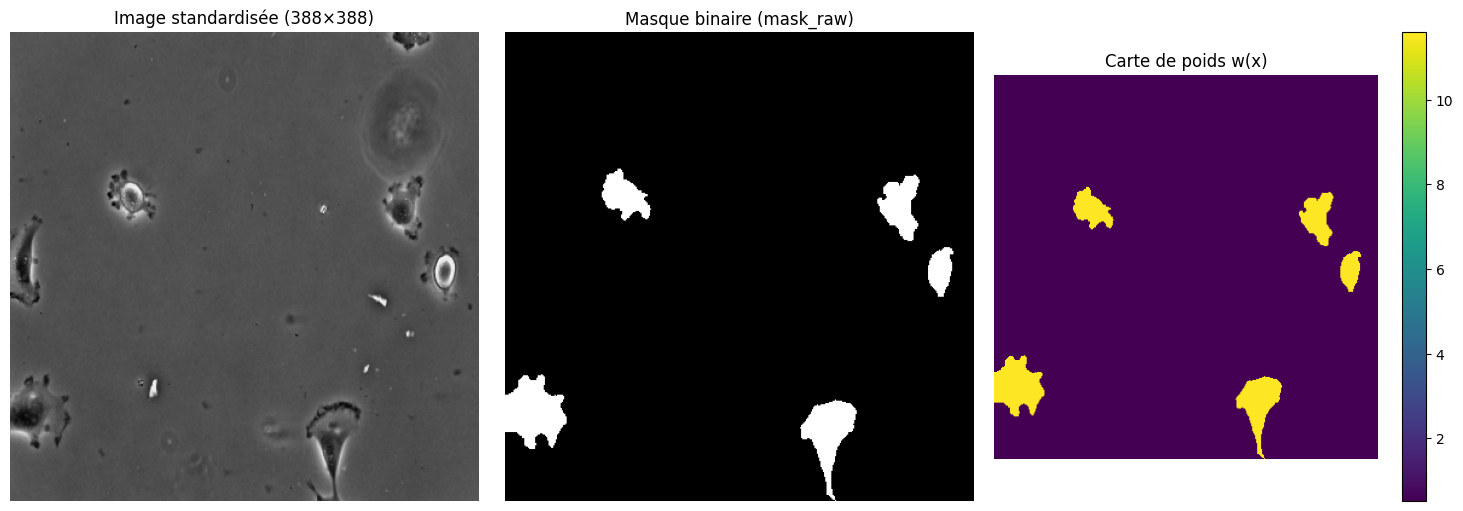

In [54]:
# Préparation des splits avec z-score calculé uniquement sur le train
train_items, TRAIN_MEAN, TRAIN_STD = prepare_split(train_pairs)
val_items, _, _   = prepare_split(val_pairs, TRAIN_MEAN, TRAIN_STD)
test_items, _, _  = prepare_split(test_pairs, TRAIN_MEAN, TRAIN_STD)

# Val / Test : images standardisées et paddées (572x572)
X_val_s  = np.stack([s["img_pad92"] for s in val_items])[..., None]
X_test_s = np.stack([s["img_pad92"] for s in test_items])[..., None]

print(f"Z-score Train -> mean={TRAIN_MEAN:.4f}, std={TRAIN_STD:.4f}")

# Aperçu de contrôle
s = train_items[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(s["img_pad92"][PAD_ORIG:-PAD_ORIG, PAD_ORIG:-PAD_ORIG], cmap="gray")
ax[0].set_title("Image standardisée (388×388)")

ax[1].imshow(s["mask_raw"], cmap="gray")
ax[1].set_title("Masque binaire (mask_raw)")

im = ax[2].imshow(s["weight"])
ax[2].set_title("Carte de poids w(x)")
plt.colorbar(im, ax=ax[2])

for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### 2.3 Augmentation des données

In [55]:
def translation(img, mask, w, rng, max_shift=MAX_SHIFT):
    """Décalage aléatoire [-max_shift, max_shift] avec réflexion sur tuiles 572x572."""
    dy, dx = int(rng.integers(-max_shift, max_shift + 1)), int(rng.integers(-max_shift, max_shift + 1))
    if dy == 0 and dx == 0:
        return img, mask, w
    h, w_dim = img.shape
    y0, x0 = max_shift - dy, max_shift - dx
    return tuple(np.pad(a, max_shift, mode="reflect")[y0:y0 + h, x0:x0 + w_dim] for a in (img, mask, w))


def rotation(img, mask, w, rng):
    """Rotation aléatoire d'un multiple de 90°."""
    k = int(rng.integers(4))
    return tuple(np.rot90(a, k) for a in (img, mask, w))


def gray_value_variation(img, rng):
    """Variation linéaire de contraste et luminosité."""
    return img * rng.uniform(0.9, 1.1) + rng.uniform(-0.1, 0.1)


def augment(s, rng):
    """Applique translation, rotation et variation de niveaux de gris sur une tuile 572x572."""
    img, mask, w = translation(s["img_pad92"], s["mask_p"], s["w_p"], rng)
    img, mask, w = rotation(img, mask, w, rng)
    return gray_value_variation(img, rng), mask, w


def make_eval_arrays(items, input_key="img_pad92", use_weights=False):
    """Prépare les tenseurs (X, Y_onehot, W) alignés sur mask_raw pour Validation / Test."""
    X = np.stack([it[input_key] for it in items], axis=0)[..., np.newaxis]
    y_bin = np.stack([it["mask_raw"] for it in items], axis=0)
    Y = keras.utils.to_categorical(y_bin, num_classes=2).astype(np.float32)
    W = np.stack([it["weight"] for it in items], axis=0).astype(np.float32) if use_weights else np.ones_like(y_bin, dtype=np.float32)
    return X, Y, W


def build_train_dataset(items, input_key="img_pad92", batch_size=BATCH_SIZE, seed=SEED):
    """Générateur tf.data d'entraînement avec augmentation et recadrage central 388x388 des cibles."""
    def generator():
        rng = np.random.default_rng(seed)
        while True:
            for idx in rng.permutation(len(items)):
                img_572, mask_572, w_572 = augment(items[idx], rng)
                sl = slice(PAD_ORIG, PAD_ORIG + IMG_SIZE)
                mask_388, w_388 = mask_572[sl, sl], w_572[sl, sl]

                if input_key == "img_pad92":
                    x_in = img_572[..., np.newaxis]
                else:
                    x_in = np.pad(img_572[sl, sl], PAD_MULT16, mode="reflect")[..., np.newaxis]

                y_oh = keras.utils.to_categorical(mask_388, num_classes=2).astype(np.float32)
                yield x_in.astype(np.float32), y_oh, w_388.astype(np.float32)

    h_in = 572 if input_key == "img_pad92" else 576
    sig = (
        tf.TensorSpec((h_in, h_in, 1), tf.float32),
        tf.TensorSpec((IMG_SIZE, IMG_SIZE, 2), tf.float32),
        tf.TensorSpec((IMG_SIZE, IMG_SIZE), tf.float32),
    )
    return tf.data.Dataset.from_generator(generator, output_signature=sig).batch(batch_size).prefetch(tf.data.AUTOTUNE)

## 3. Définitions communes

In [56]:
# Métriques personnalisées pour la segmentation binaire (cellule vs fond)
class ArgmaxIoU(keras.metrics.IoU):
    """Calcule l'IoU sur les classes discrètes issues d'argmax (corrige OneHotIoU)."""
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(tf.argmax(y_true, axis=-1), tf.argmax(y_pred, axis=-1), sample_weight=sample_weight)


class ForegroundAUC(keras.metrics.AUC):
    """Calcule l'AUC (ROC ou PR) sur la classe cellule des sorties softmax one-hot."""
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[..., 1], y_pred[..., 1], sample_weight=sample_weight)


def add_dice(s):
    return 2 * s["precision"] * s["recall"] / (s["precision"] + s["recall"] + 1e-8)


def dice_loss(y_true, y_pred):
    """Dice Loss sur la classe cellule (canal 1)."""
    yt_fg, yp_fg = y_true[..., 1], y_pred[..., 1]
    inter = tf.reduce_sum(yt_fg * yp_fg, axis=[1, 2])
    union = tf.reduce_sum(yt_fg, axis=[1, 2]) + tf.reduce_sum(yp_fg, axis=[1, 2])
    return tf.reduce_mean(1.0 - (2.0 * inter + 1e-5) / (union + 1e-5))


def focal_loss(y_true, y_pred, gamma=2.0, alpha=0.25, sample_weight=None):
    """Focal Loss pondérée pixel par pixel par w(x) pour les bordures et la classe minoritaire."""
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    focal = -tf.reduce_sum(
        y_true * (alpha * tf.pow(1.0 - y_pred, gamma) * tf.math.log(y_pred)),
        axis=-1,
    )
    if sample_weight is not None:
        focal *= tf.cast(sample_weight, tf.float32)
    return tf.reduce_mean(focal)


def weighted_focal_dice_loss(y_true, y_pred, sample_weight=None):
    """Perte combinée unifiée : Focal Loss pondérée par w(x) (0.1) + Dice Loss (0.9)."""
    f_loss = focal_loss(y_true, y_pred, gamma=2.0, alpha=0.25, sample_weight=sample_weight)
    d_loss = dice_loss(y_true, y_pred)
    return 0.1 * f_loss + 0.9 * d_loss

def plot_training_history(history, title):
    """Affiche l'évolution des métriques d'entraînement et de validation."""
    history_df = pd.DataFrame(history.history)
    epochs = range(1, len(history_df) + 1)

    metrics = ["loss", "accuracy", "precision", "recall", "auc", "auc_pr", "iou_fg", "mean_iou"]
    titles = {
        "loss": "Loss", "accuracy": "Pixel accuracy",
        "precision": "Precision (objet)", "recall": "Recall (objet)",
        "auc": "AUC (ROC)", "auc_pr": "AUC (PR)",
        "iou_fg": "IoU (objet)", "mean_iou": "Mean IoU",
    }

    fig, axes = plt.subplots(2, 4, figsize=(22, 9))
    palette = sns.color_palette("tab10", n_colors=len(metrics))

    for idx, (m_name, ax) in enumerate(zip(metrics, axes.flat)):
        if m_name not in history_df.columns:
            ax.set_visible(False)
            continue
        c = palette[idx]
        ax.plot(epochs, history_df[m_name], lw=2, color=c, label="train")
        if "val_" + m_name in history_df.columns:
            ax.plot(epochs, history_df["val_" + m_name], ls="--", color=c, label="validation")
        if m_name != "loss":
            ax.set_ylim(0, 1)
        ax.set_ylabel(titles[m_name])
        ax.set_xlabel("Epochs")
        ax.set_title(f"{titles[m_name]} through training")
        ax.grid(alpha=0.3)
        ax.legend()

    plt.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()
    return history_df


def evaluate_predictions(y_true_bin, y_prob_fg, threshold=0.5, model_name="", split_name="Test"):
    """Évalue les prédictions de manière strictement identique pour tous les modèles (DL & ML) sur mask_raw."""
    yt = y_true_bin.ravel()
    yp_prob = y_prob_fg.ravel()
    yp = (yp_prob >= threshold).astype(np.uint8)

    iou_bg = jaccard_score(yt, yp, pos_label=0, zero_division=0)
    iou_fg = jaccard_score(yt, yp, pos_label=1, zero_division=0)
    return {
        "Modèle": model_name,
        "Jeu": split_name,
        "Seuil": round(threshold, 3),
        "Accuracy": round(accuracy_score(yt, yp), 4),
        "Precision (Cell)": round(precision_score(yt, yp, zero_division=0), 4),
        "Recall (Cell)": round(recall_score(yt, yp, zero_division=0), 4),
        "Dice / F1": round(f1_score(yt, yp, zero_division=0), 4),
        "IoU Cellule": round(iou_fg, 4),
        "Mean IoU": round(0.5 * (iou_bg + iou_fg), 4),
        "AUC (ROC)": round(roc_auc_score(yt, yp_prob), 4),
        "AUC (PR)": round(average_precision_score(yt, yp_prob), 4),
    }


all_model_scores = {}
dl_histories = {}


def train_and_evaluate_dl(build_fn, model_label, input_key="img_pad92", lr=3e-4, batch_size=BATCH_SIZE, epochs=EPOCHS):
    """Entraîne un modèle DL avec gestion mémoire stricte, mesure de temps d'apprentissage et suivi sur val_loss."""
    cleanup_memory()
    model = build_fn()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=weighted_focal_dice_loss,
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.Precision(class_id=1, name="precision"),
            keras.metrics.Recall(class_id=1, name="recall"),
            ForegroundAUC(curve="ROC", name="auc"),
            ForegroundAUC(curve="PR", name="auc_pr"),
            ArgmaxIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
            ArgmaxIoU(num_classes=2, target_class_ids=[0, 1], name="mean_iou"),
        ],
        weighted_metrics=[],
    )

    train_ds = build_train_dataset(train_items, input_key=input_key, batch_size=batch_size)
    X_val, Y_val, W_val = make_eval_arrays(val_items, input_key=input_key, use_weights=True)
    X_test, _, _ = make_eval_arrays(test_items, input_key=input_key, use_weights=False)
    y_val_bin = np.stack([it["mask_raw"] for it in val_items], axis=0)
    y_test_bin = np.stack([it["mask_raw"] for it in test_items], axis=0)

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=PATIENCE, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", mode="min", factor=0.5, patience=4, min_lr=1e-6, verbose=1
        ),
    ]

    print(f"\n{'='*65}\nEntraînement : {model_label}\n{'='*65}")
    t0 = time.perf_counter()
    history = model.fit(
        train_ds,
        steps_per_epoch=max(1, len(train_items) // batch_size),
        epochs=epochs,
        validation_data=(X_val, Y_val, W_val),
        callbacks=callbacks,
        verbose=1,
    )
    train_time = round(time.perf_counter() - t0, 1)

    history_df = plot_training_history(history, title=f"Historique d'entraînement — {model_label}")

    val_probs = model.predict(X_val, batch_size=batch_size, verbose=0)[..., 1]
    best_th = 0.5
    val_scores = evaluate_predictions(y_val_bin, val_probs, threshold=best_th, model_name=model_label, split_name="Validation")

    test_probs = model.predict(X_test, batch_size=batch_size, verbose=0)[..., 1]
    test_scores = evaluate_predictions(y_test_bin, test_probs, threshold=best_th, model_name=model_label, split_name="Test")
    test_scores["Temps (s)"] = train_time
    test_scores["Params (M)"] = round(model.count_params() / 1e6, 2)

    all_model_scores[model_label] = {k: v for k, v in test_scores.items() if k != "Jeu"}
    dl_histories[model_label] = history.history

    df_res = pd.DataFrame([val_scores, test_scores]).set_index(["Modèle", "Jeu"])
    display(df_res.style.format("{:.4f}", subset=[c for c in df_res.columns if c not in ("Seuil", "Params (M)")]))

    cleanup_memory([model, train_ds, history, X_val, Y_val, W_val, X_test])
    return test_scores, history_df

## 4. U-Net
  Le but de ce projet est de développer un réseau de neurones appelé U-Net, dont la structure en forme de U lui donne son nom, et de comparer ses performances à celles de réseaux plus simples. Nous souhaitons déterminer si, dans le cadre de la segmentation d'images biomédicales, il est nécessaire de développer des architectures aussi complexes pour obtenir des performances satisfaisantes.

  Dans un premier temps, nous développerons le réseau U-Net et ses variantes, dont une version avec ASPP. Nous comparerons ensuite ces architectures à un réseau convolutionnel simple, à un décodeur inspiré de ResNet-50, à DeepLabV3+ et à des méthodes classiques de machine learning (Random Forest et XGBoost). Aucune architecture Inception n'est implémentée dans ce notebook.

  Les données utilisées sont celles de la séquence de microscopie cellulaire PhC-C2DH-U373 (jeu de données de segmentation de cellules). L'objectif est une segmentation binaire au niveau des pixels : distinguer les cellules de l'arrière-plan, et non détecter un cancer ou analyser des mammographies.

  Les performances sont évaluées par la loss, l'accuracy, la precision, le recall, le Dice/F1 pixel, l'IoU de la classe cellule, le Mean IoU, l'AUC ROC et l'AUC PR. L'accuracy seule peut être trompeuse lorsque l'arrière-plan est majoritaire ; le Dice, l'IoU et l'AUC PR renseignent davantage sur la classe cellule et son recouvrement avec la vérité terrain.

  Afin de garantir la reproductibilité des résultats et la comparabilité des modèles, une seed globale est fixée pour l'ensemble du notebook.

### 4.1 U-Net original

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau U-Net est un réseau de neurones convolutif dont l'architecture repose sur deux parties complémentaires : un encodeur, qui réduit progressivement la résolution spatiale de l'image, et un décodeur, qui permet de reconstruire progressivement sa résolution initiale grâce à des convolutions transposées (up-convolutions).

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur est composé de quatre blocs successifs. Chacun de ces blocs contient deux couches de convolution de taille 3 × 3, suivies d'une fonction d'activation ReLU. À la fin de chaque bloc, une opération de max pooling de taille 2 × 2 est appliquée afin de réduire de moitié la résolution spatiale de l'image et d'extraire des caractéristiques de plus en plus abstraites.

&nbsp;&nbsp;&nbsp;&nbsp; Une particularité essentielle de l'architecture U-Net réside dans ses connexions de saut (skip connections). À la sortie de chaque bloc de l'encodeur, les caractéristiques extraites sont copiées puis recadrées (cropped) afin d'être transmises au bloc correspondant du décodeur. Ces connexions permettent de conserver les informations spatiales détaillées perdues lors de la réduction de résolution et de les réutiliser pendant la reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le bloc le plus profond du réseau, situé entre l'encodeur et le décodeur, constitue le point de transition de l'architecture. Il est composé de deux couches de convolution de taille 3 × 3, chacune suivie d'une fonction d'activation ReLU. Il permet d'extraire les caractéristiques les plus abstraites de l'image avant d'entamer la phase de reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le décodeur constitue la seconde partie du réseau. À chaque étage, la résolution spatiale est augmentée grâce à une convolution transposée (up-convolution) de taille 2 × 2. Les caractéristiques obtenues sont ensuite concaténées avec celles provenant de la connexion de saut correspondante de l'encodeur. Chaque bloc du décodeur est alors composé de deux couches de convolution de taille 3 × 3, suivies chacune d'une fonction d'activation ReLU.

&nbsp;&nbsp;&nbsp;&nbsp; Enfin, une dernière convolution 1 x 1 permet de projeter les caractéristiques obtenues sur le nombre de classes souhaité, afin d'attribuer à chaque pixel de l'image une classe et de produire ainsi la segmentation finale.

In [19]:
# Définition des blocs de convolution et up-convolution
def conv_block(x: tf.Tensor, filters: int) -> tf.Tensor:
    """Deux couches de convolution 3x3 suivies d'une activation ReLU (sans padding)."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    return x


def up_block(x: tf.Tensor, skip: tf.Tensor, filters: int, crop: int) -> tf.Tensor:
    """Sur-échantillonnage 2x2, recadrage du skip, concaténation puis conv_block."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2)(x)
    skip = keras.layers.Cropping2D(crop)(skip)
    x = keras.layers.Concatenate()([skip, x])
    return conv_block(x, filters)

# Définition du modèle U-Net
def get_unet_original(input_shape=(572, 572, 1), num_classes=2) -> keras.Model:
    """Retourne le modèle U-Net original conforme à l'architecture de référence."""
    inputs = keras.Input(input_shape)

    # Encodeur
    x1 = conv_block(inputs, 64)
    x2 = conv_block(keras.layers.MaxPooling2D(2)(x1), 128)
    x3 = conv_block(keras.layers.MaxPooling2D(2)(x2), 256)
    x4 = conv_block(keras.layers.MaxPooling2D(2)(x3), 512)

    # Bottleneck
    b = conv_block(keras.layers.MaxPooling2D(2)(x4), 1024)

    # Décodeur
    d4 = up_block(b, x4, 512, crop=4)
    d3 = up_block(d4, x3, 256, crop=16)
    d2 = up_block(d3, x2, 128, crop=40)
    d1 = up_block(d2, x1, 64, crop=88)

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)

    return keras.Model(inputs, outputs, name="unet_original")


unet_original = get_unet_original()
unet_original.summary()

Model: "unet_original"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 570, 570, 64  640         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 568, 568, 64  36928       ['conv2d[0][0]']                 
                                )                                                     


Entraînement : U-Net original
Epoch 1/20
36/36 [==============================] - 20s 488ms/step - loss: 0.7394 - accuracy: 0.4461 - precision: 0.1028 - recall: 0.9465 - auc: 0.9101 - auc_pr: 0.5235 - iou_fg: 0.4235 - mean_iou: 0.3936 - val_loss: 0.5867 - val_accuracy: 0.9417 - val_precision: 0.6249 - val_recall: 0.3365 - val_auc: 0.7632 - val_auc_pr: 0.3695 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 2/20
36/36 [==============================] - 16s 454ms/step - loss: 0.1906 - accuracy: 0.9731 - precision: 0.7631 - recall: 0.8659 - auc: 0.9462 - auc_pr: 0.7427 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.1368 - val_accuracy: 0.9807 - val_precision: 0.8367 - val_recall: 0.8867 - val_auc: 0.9511 - val_auc_pr: 0.7961 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 3/20
36/36 [==============================] - 16s 454ms/step - loss: 0.1207 - accuracy: 0.9829 - precision: 0.8361 - recall: 0.9212 - auc: 0.9674 - auc_pr: 0.8239 - iou_fg: 0.3333

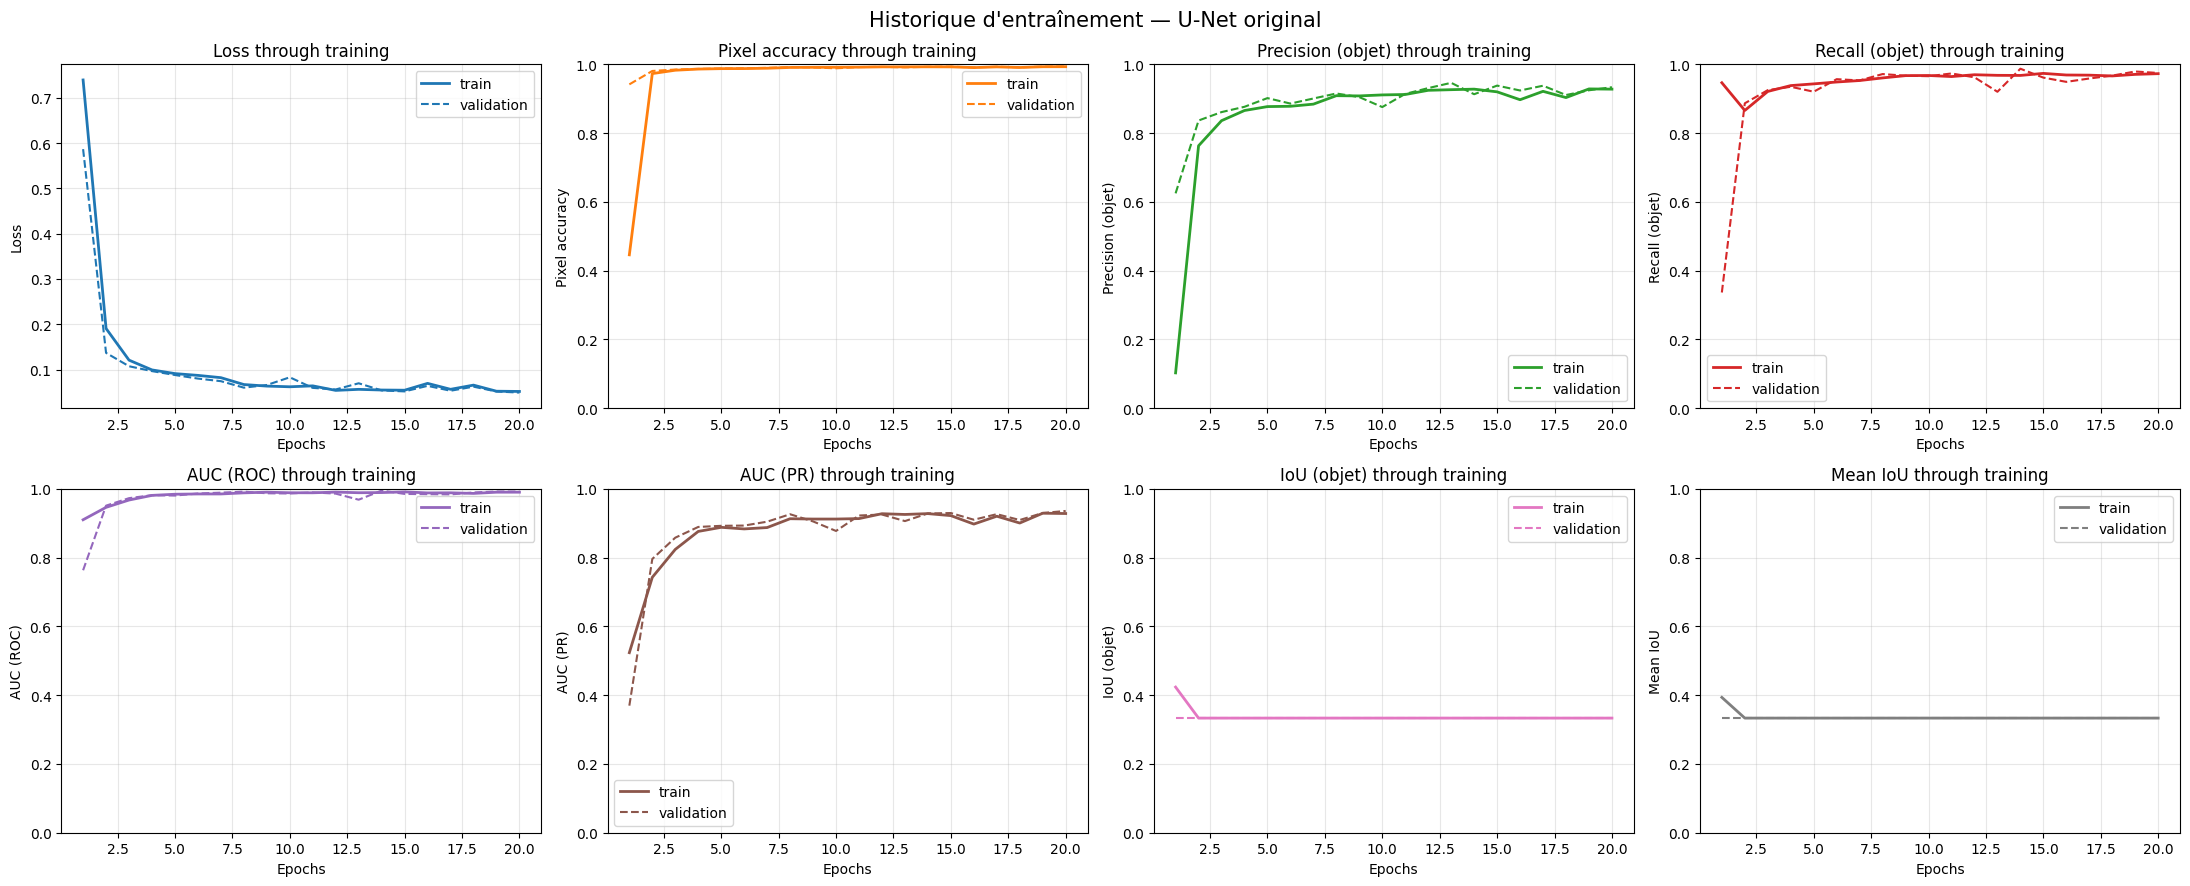

In [20]:
# Entraînement et évaluation du modèle U-Net original
score_unet_original, history_df_unet_original = train_and_evaluate_dl(
    get_unet_original,
    model_label="U-Net original",
    input_key="img_pad92",
)

In [22]:
# Nettoyage mémoire pour sauvegarder de la RAM
cleanup_memory()

### 4.2 U-Net simplifié

&nbsp;&nbsp;&nbsp;&nbsp; L'idée derrière cette variante du U-Net original est de réduire la complexité et le risque de surapprentissage du modèle en supprimant l'étage le plus profond à 1024 filtres, tout en renforçant la régularisation interne. Sur un jeu de données biomédical de taille limitée, un réseau trop profond a tendance à mémoriser les exemples d'entraînement ; cette architecture plus compacte à trois étages (64 à 512 filtres) permet d'alléger considérablement le nombre de paramètres et d'accélérer l'entraînement.

&nbsp;&nbsp;&nbsp;&nbsp; Pour compenser cette réduction de profondeur et stabiliser la convergence, les blocs de convolution remplacent l'activation ReLU classique par la fonction SiLU, couplée à une BatchNormalization et à un Dropout de 20 %. Le réseau conserve le principe des convolutions sans padding et des rskip connections, avec un Cropping2D final en sortie pour ramener la prédiction à la résolution exacte des masques (388 × 388 pixels).

In [23]:
def conv_block_simplified(x: tf.Tensor, filters: int) -> tf.Tensor:
    """Bloc de convolution avec activation SiLU, Batch Normalization et Dropout."""
    x = keras.layers.Conv2D(filters, 3, activation="silu", padding="valid")(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Conv2D(filters, 3, activation="silu", padding="valid")(x)
    return x


def up_block_simplified(x: tf.Tensor, skip: tf.Tensor, filters: int, crop: int) -> tf.Tensor:
    """Étape de décodage simplifiée pour le modèle U-Net compact."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="valid")(x)
    skip = keras.layers.Cropping2D(cropping=((crop, crop), (crop, crop)))(skip)
    x = keras.layers.Concatenate()([skip, x])
    return conv_block_simplified(x, filters)


def get_unet_simplified(input_shape=(572, 572, 1), num_classes=2) -> keras.Model:
    """Retourne la version compacte et régularisée du U-Net."""
    inputs = keras.Input(shape=input_shape)

    # Encodeur
    x1 = conv_block_simplified(inputs, 64)
    x2 = conv_block_simplified(keras.layers.MaxPooling2D(2)(x1), 128)
    x3 = conv_block_simplified(keras.layers.MaxPooling2D(2)(x2), 256)

    # Bottleneck
    b = conv_block_simplified(keras.layers.MaxPooling2D(2)(x3), 512)

    # Décodeur
    d3 = up_block_simplified(b, x3, 256, crop=4)
    d2 = up_block_simplified(d3, x2, 128, crop=16)
    d1 = up_block_simplified(d2, x1, 64, crop=40)

    # Recadrage et projection
    d1_cropped = keras.layers.Cropping2D(cropping=((48, 48), (48, 48)))(d1)
    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax", padding="valid")(d1_cropped)

    return keras.Model(inputs, outputs, name="unet_simplified")


unet_simplified = get_unet_simplified()
unet_simplified.summary()

Model: "unet_simplified"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 570, 570, 64  640         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 570, 570, 64  256        ['conv2d[0][0]']                 
 alization)                     )                                                   


Entraînement : U-Net simplifié
Epoch 1/20
36/36 [==============================] - 35s 905ms/step - loss: 0.3053 - accuracy: 0.9430 - precision: 0.5422 - recall: 0.9255 - auc: 0.9563 - auc_pr: 0.6918 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8961 - val_accuracy: 0.9327 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.5944 - val_auc_pr: 0.2595 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500 - lr: 3.0000e-04
Epoch 2/20
36/36 [==============================] - 31s 874ms/step - loss: 0.0963 - accuracy: 0.9866 - precision: 0.8734 - recall: 0.9356 - auc: 0.9773 - auc_pr: 0.8660 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.9140 - val_accuracy: 0.9327 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.5005 - val_auc_pr: 0.0685 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500 - lr: 3.0000e-04
Epoch 3/20
36/36 [==============================] - 32s 886ms/step - loss: 0.0756 - accuracy: 0.9900 - precision: 0.9023 - recall: 0.9523 - auc: 0.9843 - auc_pr

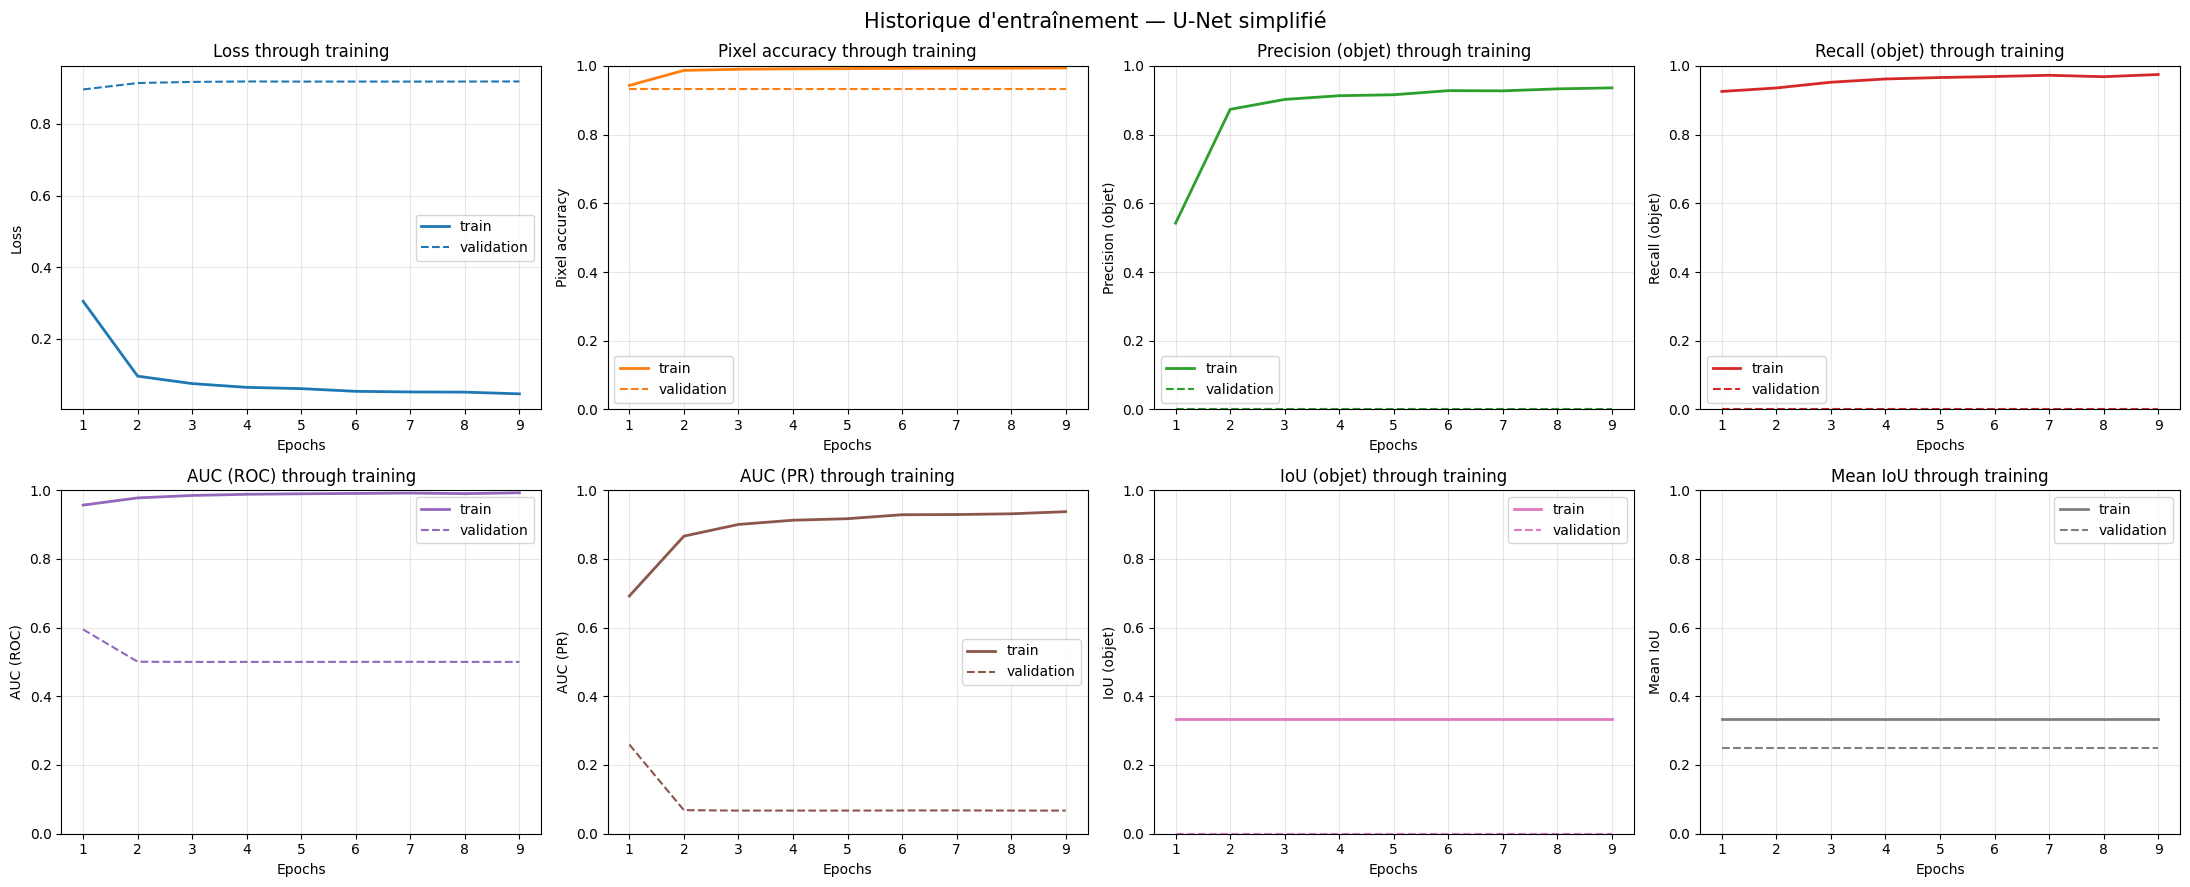

In [24]:
# Entraînement et évaluation du modèle U-Net simplifié
score_unet_simplified, history_df_unet_simplified = train_and_evaluate_dl(
    get_unet_simplified,
    model_label="U-Net simplifié",
    input_key="img_pad92",
)

In [25]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

&nbsp;&nbsp;&nbsp;&nbsp; Les résultats sur le validation set et le early stopping montrent un overfitting très important. Cela n'a rien de surprenant car le faible nombre de parametres fait que le model à tendance à surpredire le fond d'image ce qui a tendance à grandemant dégrader nos résultats.  

### 4.3 U-Net avec padding

&nbsp;&nbsp;&nbsp;&nbsp; L'idée derrière cette variante du U-Net est de se débarrasser de la contrainte de *cropping* systématique à chaque étage en imposant un *padding* sur l'ensemble des convolutions. On revient ainsi simplement à des divisions par 2 lors des opérations de *max pooling*, ce qui permet de remonter symétriquement dans le décodeur sans perte de pixels aux bordures et en allégeant le nombre de filtres (de 32 à 512).

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur et le *bottleneck* conservent la structure à quatre étages du U-Net original, mais chaque double convolution 3 × 3 maintient la taille spatiale de la carte de caractéristiques. Les *skip connections* transmettent directement ces caractéristiques au décodeur, où un simple redimensionnement  corrige uniquement le décalage d'un pixel dû aux dimensions impaires issues du *pooling* (572 → 286 → 143 → 71 → 35).

&nbsp;&nbsp;&nbsp;&nbsp; Bien que cette technique introduise de la « fausse » information (des zéros ajoutés sur les bords) à toutes les étapes de l'encodeur, elle reste très pertinente à tester car elle simplifie nettement l'architecture et la gestion des dimensions. Un unique *cropping* final  en sortie ramène la prédiction de 572 × 572 à 388 × 388 pixels avant la convolution 1 × 1 de classification.


In [26]:
def conv_block_same(x: tf.Tensor, filters: int) -> tf.Tensor:
    """Convolutions 3x3 préservant les dimensions spatiales (padding='same')."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="same")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="same")(x)
    return x


def up_block_same(x: tf.Tensor, skip: tf.Tensor, filters: int) -> tf.Tensor:
    """Upsampling suivi d'un redimensionnement dynamique avant concaténation."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    target_height, target_width = skip.shape[1], skip.shape[2]
    x = keras.layers.Resizing(target_height, target_width)(x)
    x = keras.layers.Concatenate()([skip, x])
    return conv_block_same(x, filters)


def get_unet_padding(input_shape=(572, 572, 1), num_classes=2) -> keras.Model:
    """U-Net exploitant des convolutions 'same' avec recadrage de sortie."""
    inputs = keras.Input(shape=input_shape)

    # Encodeur
    x1 = conv_block_same(inputs, 32)
    x2 = conv_block_same(keras.layers.MaxPooling2D(2)(x1), 64)
    x3 = conv_block_same(keras.layers.MaxPooling2D(2)(x2), 128)
    x4 = conv_block_same(keras.layers.MaxPooling2D(2)(x3), 256)

    # Bottleneck
    b = conv_block_same(keras.layers.MaxPooling2D(2)(x4), 512)

    # Décodeur
    d4 = up_block_same(b, x4, 256)
    d3 = up_block_same(d4, x3, 128)
    d2 = up_block_same(d3, x2, 64)
    d1 = up_block_same(d2, x1, 32)

    d1_resized = keras.layers.Resizing(input_shape[0], input_shape[1])(d1)
    d1_cropped = keras.layers.Cropping2D(((92, 92), (92, 92)))(d1_resized)
    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1_cropped)

    return keras.Model(inputs, outputs, name="unet_padding")


unet_padding = get_unet_padding()
unet_padding.summary()

Model: "unet_padding"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 572, 572, 32  320         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 572, 572, 32  9248        ['conv2d[0][0]']                 
                                )                                                      


Entraînement : U-Net padding
Epoch 1/20
36/36 [==============================] - 11s 263ms/step - loss: 0.7560 - accuracy: 0.3359 - precision: 0.0847 - recall: 0.9147 - auc: 0.8625 - auc_pr: 0.4927 - iou_fg: 0.4235 - mean_iou: 0.3894 - val_loss: 0.7253 - val_accuracy: 0.8674 - val_precision: 0.3358 - val_recall: 0.9908 - val_auc: 0.9756 - val_auc_pr: 0.6414 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 2/20
36/36 [==============================] - 8s 234ms/step - loss: 0.2978 - accuracy: 0.9594 - precision: 0.6452 - recall: 0.8716 - auc: 0.9329 - auc_pr: 0.6991 - iou_fg: 0.3396 - mean_iou: 0.3396 - val_loss: 0.1627 - val_accuracy: 0.9779 - val_precision: 0.8446 - val_recall: 0.8229 - val_auc: 0.9317 - val_auc_pr: 0.7857 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 3/20
36/36 [==============================] - 8s 235ms/step - loss: 0.1388 - accuracy: 0.9801 - precision: 0.8159 - recall: 0.9035 - auc: 0.9625 - auc_pr: 0.8102 - iou_fg: 0.3333 - 

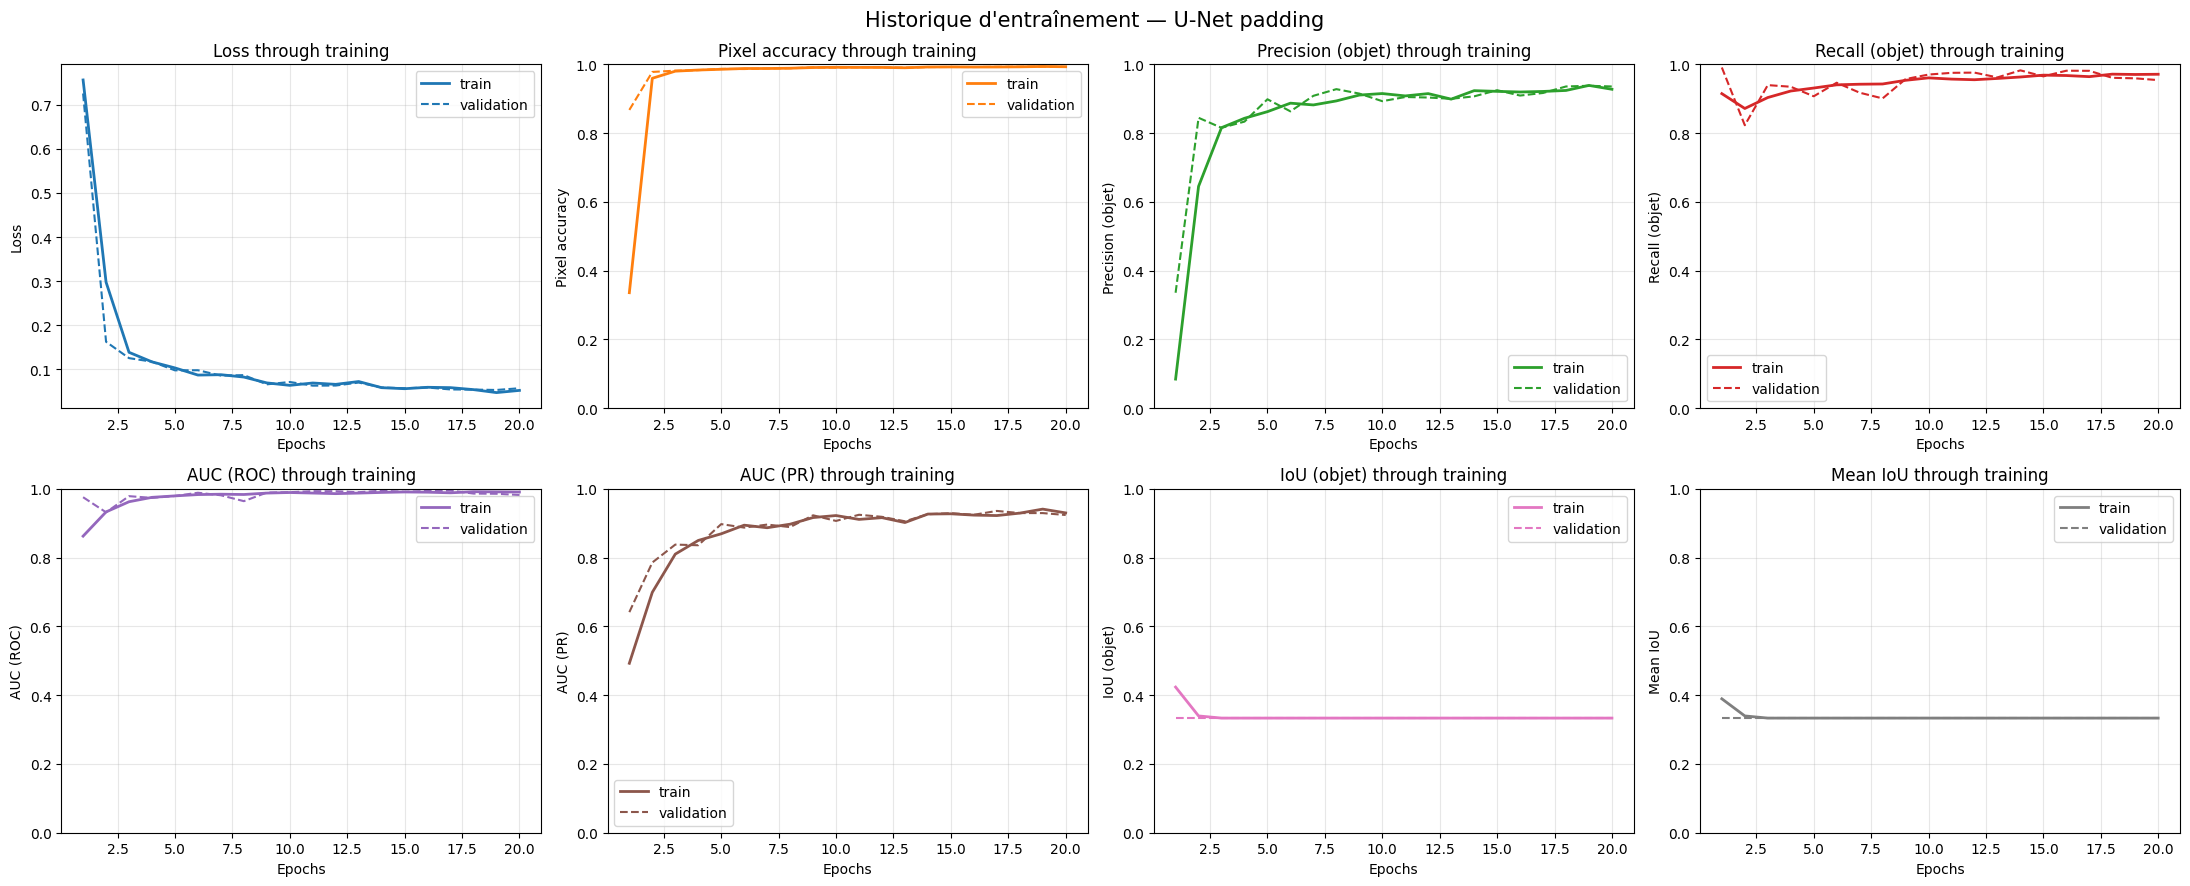

In [27]:
# Entraînement et évaluation du modèle U-Net avec padding
score_unet_padding, history_df_unet_padding = train_and_evaluate_dl(
    get_unet_padding,
    model_label="U-Net padding",
    input_key="img_pad92",
)

In [28]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

&nbsp;&nbsp;&nbsp;&nbsp; De même que pour le U-Net simplifié, les résultats sur le validation set et le early stopping montrent un overfitting très important. Pour les mêmes raisons que pour le U-Net simplifié, les modification apportés pour tanter de contre balancer ce sur-apprentissage ne compense pas la trop grande perde de paramettres.

### 4.4 U-Net avec ASPP

&nbsp;&nbsp;&nbsp;&nbsp; Cette variante conserve un encodeur-décodeur U-Net avec des convolutions et Batch Normalization, et ajoute un véritable module ASPP au bottleneck. Celui-ci réunit une convolution 1 × 1, trois convolutions 3 × 3 dilatées (taux 6, 12 et 18) ainsi qu'une branche de pooling global redimensionnée, puis fusionne leurs caractéristiques par concaténation et projection 1 × 1.

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur et le bottleneck conservent quatre niveaux de pooling. Les skip connections transmettent les caractéristiques au décodeur, où le redimensionnement corrige les dimensions impaires avant concaténation. Le cropping final extrait la zone centrale 388 × 388, alignée sur le masque.

&nbsp;&nbsp;&nbsp;&nbsp; L'ASPP permet d'intégrer des informations à plusieurs échelles dans le champ réceptif du bottleneck. La convolution finale produit les classes par pixel après le recadrage central.

In [29]:
# Module Atrous Spatial Pyramid Pooling
def aspp_module(x, filters=512, rates=(6, 12, 18)):
    """Fusionne des convolutions multi-échelles et une branche de pooling global."""
    branches = [keras.layers.Conv2D(filters, 1, padding="same", activation="relu")(x)]
    for rate in rates:
        branches.append(
            keras.layers.Conv2D(
                filters, 3, padding="same", dilation_rate=rate, activation="relu"
            )(x)
        )
    pool = keras.layers.GlobalAveragePooling2D(keepdims=True)(x)
    pool = keras.layers.Conv2D(filters, 1, activation="relu")(pool)
    pool = keras.layers.Resizing(x.shape[1], x.shape[2])(pool)
    branches.append(pool)
    x = keras.layers.Concatenate()(branches)
    return keras.layers.Conv2D(filters, 1, padding="same", activation="relu")(x)


# Définition du modèle U-Net avec ASPP
def get_unet_aspp(input_shape=(572, 572, 1), num_classes=2) -> keras.Model:
    """Architecture U-Net avec ASPP au bottleneck et recadrage final."""
    inputs = keras.Input(shape=input_shape)

    # Définition du bloc de convolution élémentaire
    def aspp_conv_block(tensor: tf.Tensor, filters: int) -> tf.Tensor:
        """Une couche de convolution 3x3 avec padding 'same' suivie d'une BatchNormalization."""
        tensor = keras.layers.Conv2D(filters, 3, activation="relu", padding="same")(tensor)
        tensor = keras.layers.BatchNormalization()(tensor)
        return tensor

    # Encodeur
    x1 = aspp_conv_block(inputs, 32)
    x2 = aspp_conv_block(keras.layers.MaxPooling2D(2)(x1), 64)
    x3 = aspp_conv_block(keras.layers.MaxPooling2D(2)(x2), 128)
    x4 = aspp_conv_block(keras.layers.MaxPooling2D(2)(x3), 256)

    # Bottleneck
    bottleneck = aspp_conv_block(keras.layers.MaxPooling2D(2)(x4), 512)
    bottleneck = aspp_module(bottleneck, 512)

    # Décodeur (sur-échantillonnage, alignement spatial, concaténation puis convolution)
    u4 = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(bottleneck)
    u4 = keras.layers.Resizing(x4.shape[1], x4.shape[2])(u4)
    u4 = keras.layers.Concatenate()([u4, x4])
    u4 = aspp_conv_block(u4, 256)

    u3 = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u4)
    u3 = keras.layers.Resizing(x3.shape[1], x3.shape[2])(u3)
    u3 = keras.layers.Concatenate()([u3, x3])
    u3 = aspp_conv_block(u3, 128)

    u2 = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u3)
    u2 = keras.layers.Resizing(x2.shape[1], x2.shape[2])(u2)
    u2 = keras.layers.Concatenate()([u2, x2])
    u2 = aspp_conv_block(u2, 64)

    u1 = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u2)
    u1 = keras.layers.Resizing(x1.shape[1], x1.shape[2])(u1)
    u1 = keras.layers.Concatenate()([u1, x1])
    u1 = aspp_conv_block(u1, 32)

    # Recadrage final (572x572 -> 388x388) et couche de classification pixel par pixel
    u1_cropped = keras.layers.Cropping2D(((92, 92), (92, 92)))(u1)
    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u1_cropped)

    return keras.Model(inputs, outputs, name="unet_aspp")


unet_aspp = get_unet_aspp()
unet_aspp.summary()

Model: "unet_aspp"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 572, 572, 32  320         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 572, 572, 32  128        ['conv2d[0][0]']                 
 alization)                     )                                                         


Entraînement : U-Net ASPP
Epoch 1/20
36/36 [==============================] - 12s 264ms/step - loss: 0.5035 - accuracy: 0.8134 - precision: 0.2491 - recall: 0.8947 - auc: 0.9281 - auc_pr: 0.6314 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.7658 - val_accuracy: 0.9389 - val_precision: 0.8756 - val_recall: 0.1084 - val_auc: 0.7879 - val_auc_pr: 0.5146 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 2/20
36/36 [==============================] - 8s 236ms/step - loss: 0.1234 - accuracy: 0.9844 - precision: 0.8488 - recall: 0.9324 - auc: 0.9905 - auc_pr: 0.8938 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.7464 - val_accuracy: 0.9368 - val_precision: 0.8107 - val_recall: 0.0791 - val_auc: 0.8697 - val_auc_pr: 0.5718 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 3/20
36/36 [==============================] - 8s 234ms/step - loss: 0.0849 - accuracy: 0.9891 - precision: 0.8916 - recall: 0.9513 - auc: 0.9930 - auc_pr: 0.9206 - iou_fg: 0.3333 - mea

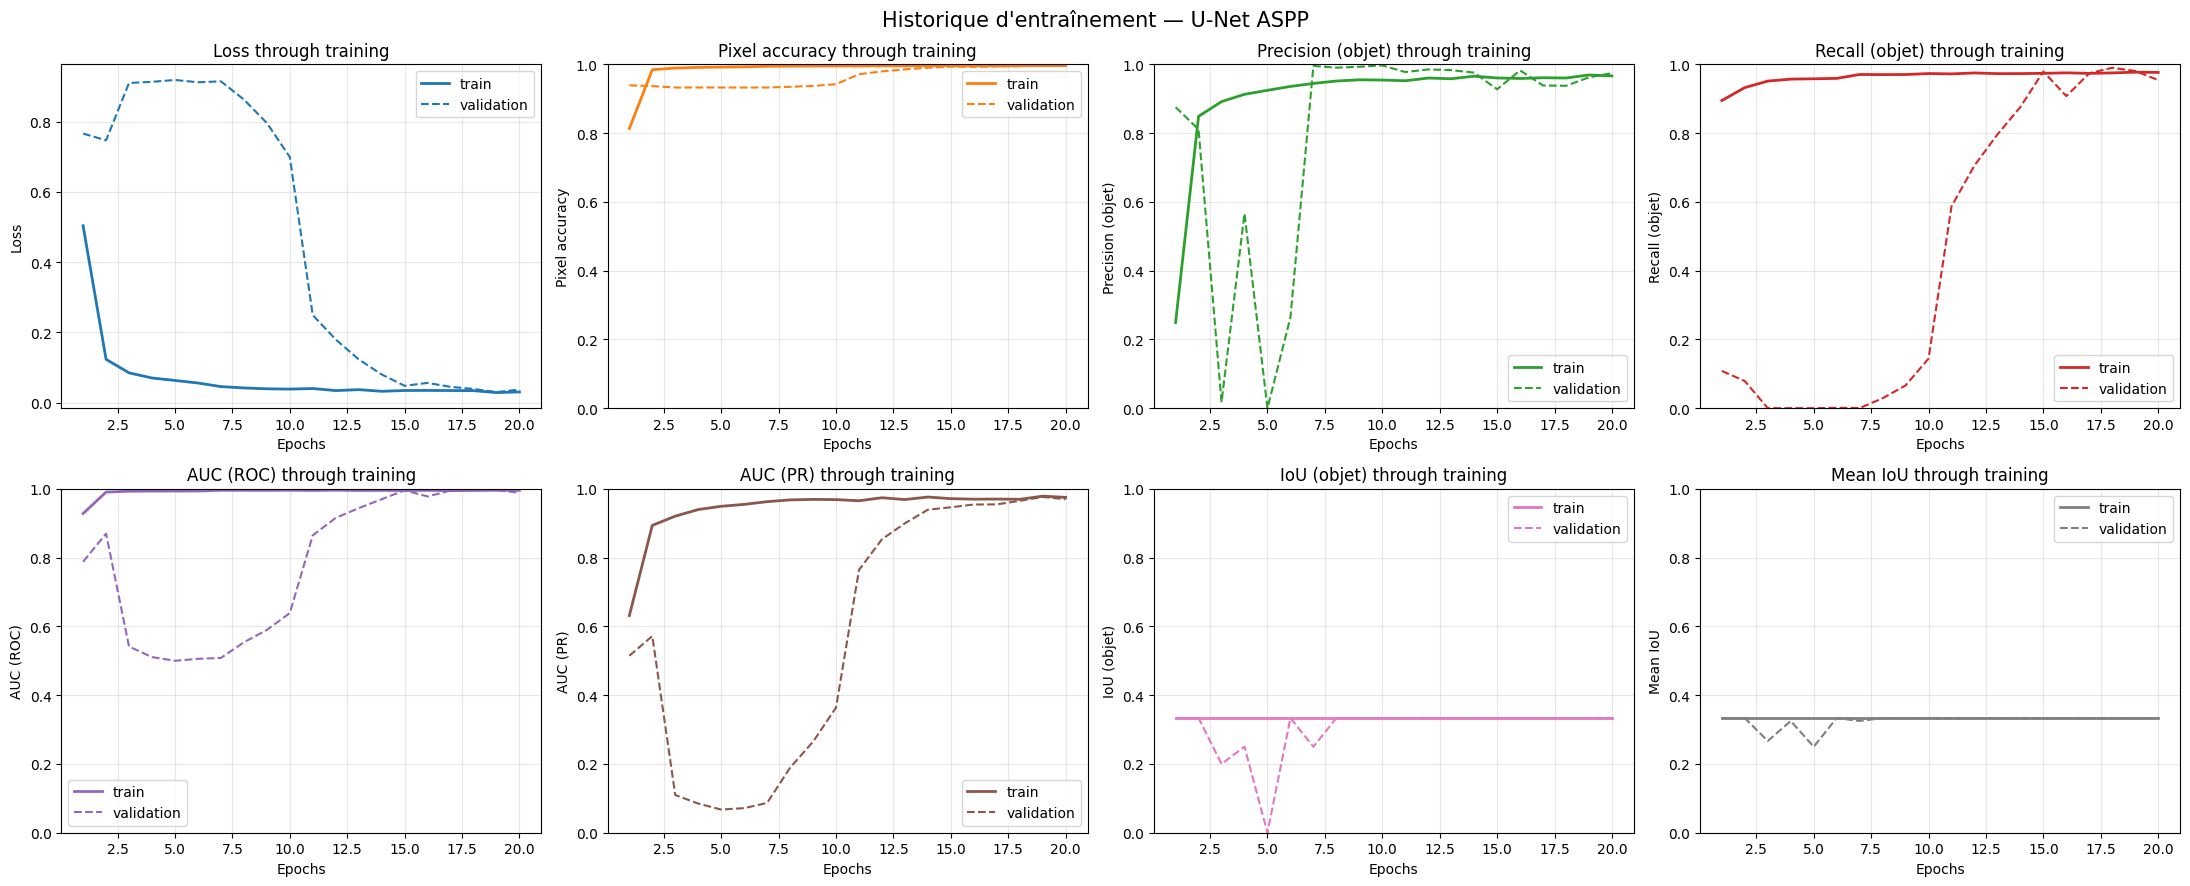

In [30]:
# Entraînement et évaluation du modèle U-Net avec ASPP
score_unet_aspp, history_df_unet_aspp = train_and_evaluate_dl(
    get_unet_aspp,
    model_label="U-Net ASPP",
    input_key="img_pad92",
)

In [31]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

## 5. ResNet

### 5.1 ResNet-50

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau ResNet50_Segmentation est un réseau de neurones convolutif destiné à la segmentation d'images. Il s'inspire de l'architecture ResNet-50 et repose sur des blocs résiduels (bottleneck blocks), qui permettent de faciliter l'apprentissage des réseaux profonds grâce à des connexions de raccourci (shortcut connections).

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau commence par une convolution de taille 7 × 7 avec 64 filtres et un pas de 2, suivie d'une opération de max pooling de taille 3 × 3. Cette première étape permet de réduire la résolution spatiale de l'image tout en extrayant les premières caractéristiques.

&nbsp;&nbsp;&nbsp;&nbsp; L'extraction des caractéristiques repose ensuite sur quatre groupes de blocs résiduels contenant respectivement 3, 4, 6 et 3 blocs. Chaque bloc est composé de trois convolutions successives de tailles 1 × 1, 3 × 3 et 1 × 1. Des couches de Batch Normalization et de Dropout (0,2) sont intégrées après les convolutions afin de stabiliser l'apprentissage et de limiter le surapprentissage. Les connexions résiduelles permettent quant à elles de transmettre directement les informations d'entrée vers la sortie de chaque bloc.

&nbsp;&nbsp;&nbsp;&nbsp; Contrairement à la ResNet-50 originale, qui se termine par une couche de classification, cette architecture utilise un décodeur avec skip connections et convolutions transposées successives. La dernière Conv2DTranspose (32 filtres, noyau 2 × 2, pas 2) ramène la carte à 572 × 572 ; un cropping de 92 pixels sur chaque bord extrait la zone centrale 388 × 388, alignée sur le masque, puis une convolution 1 × 1 avec Softmax prédit les deux classes.

&nbsp;&nbsp;&nbsp;&nbsp; La principale différence entre ResNet-50 et notre architecture réside donc dans leur objectif final. ResNet-50 est initialement conçue pour la classification d'images et utilise une couche de pooling global suivie d'une couche dense pour prédire une classe. Notre modèle conserve la structure résiduelle de ResNet-50, mais remplace cette partie de classification par un décodeur simplifié permettant d'effectuer une segmentation pixel par pixel. De plus, nous avons ajouté des couches de Dropout avec un taux de 0,2 dans les blocs résiduels afin de limiter le surapprentissage.

In [32]:
# Définition du bloc résiduel (bottleneck)
def bottleneck_block(x: tf.Tensor, filters: int, stride: int = 1) -> tf.Tensor:
    """Bloc résiduel (1x1 -> 3x3 -> 1x1) avec BatchNormalization, Dropout et connexion résiduelle."""
    shortcut = x

    # Première convolution 1x1 (réduction de dimension)
    x = keras.layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Activation("relu")(x)

    # Deuxième convolution 3x3 (extraction spatiale)
    x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Activation("relu")(x)

    # Troisième convolution 1x1 (expansion des filtres x4)
    x = keras.layers.Conv2D(filters * 4, 1, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)

    # Projection du raccourci (shortcut) si la résolution ou le nombre de canaux change
    if stride != 1 or shortcut.shape[-1] != filters * 4:
        shortcut = keras.layers.Conv2D(filters * 4, 1, strides=stride,
                                        padding="same", use_bias=False)(shortcut)
        shortcut = keras.layers.BatchNormalization()(shortcut)

    # Addition résiduelle et activation finale
    x = keras.layers.Add()([x, shortcut])
    return keras.layers.Activation("relu")(x)


# Définition du modèle hybride ResNet-50 pour la segmentation
def get_resnet50(input_shape=(572, 572, 1), num_classes=2) -> keras.Model:
    """Encodeur inspiré de ResNet-50 couplé à un décodeur progressif avec skip connections."""
    inputs = keras.layers.Input(shape=input_shape)

    # Encodeur - Niveau 1 (Résolution / 2)
    x1 = keras.layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False)(inputs)
    x1 = keras.layers.BatchNormalization()(x1)
    x1 = keras.layers.Activation("relu")(x1)

    # Encodeur - Niveau 2 (Résolution / 4)
    x2 = keras.layers.MaxPooling2D(3, strides=2, padding="same")(x1)
    for _ in range(3):
        x2 = bottleneck_block(x2, 64)

    # Encodeur - Niveau 3 (Résolution / 8)
    x3 = bottleneck_block(x2, 128, stride=2)
    for _ in range(3):
        x3 = bottleneck_block(x3, 128)

    # Encodeur - Niveau 4 (Résolution / 16)
    x4 = bottleneck_block(x3, 256, stride=2)
    for _ in range(5):
        x4 = bottleneck_block(x4, 256)

    # Bottleneck le plus profond (Résolution / 32)
    b = bottleneck_block(x4, 512, stride=2)
    for _ in range(2):
        b = bottleneck_block(b, 512)

    # Décodeur progressif avec sur-échantillonnage et concaténation des skip connections
    u1 = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)
    u1 = keras.layers.Concatenate()([u1, x4])
    u1 = keras.layers.Conv2D(256, 3, padding="same", activation="relu")(u1)

    u2 = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u1)
    u2 = keras.layers.Concatenate()([u2, x3])
    u2 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(u2)

    u3 = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u2)
    u3 = keras.layers.Resizing(143, 143)(u3)
    u3 = keras.layers.Concatenate()([u3, x2])
    u3 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(u3)

    # Remontée finale à la résolution des masques (388x388) et classification pixel par pixel
    u4 = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u3)
    u5 = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u4)
    u5 = keras.layers.Cropping2D(92)(u5)

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u5)

    return keras.Model(inputs, outputs, name="resnet50")


resnet50 = get_resnet50()
resnet50.summary()

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 286, 286, 64  3136        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 286, 286, 64  256        ['conv2d[0][0]']                 
 alization)                     )                                                          


Entraînement : ResNet-50
Epoch 1/20
36/36 [==============================] - 16s 293ms/step - loss: 0.4293 - accuracy: 0.8430 - precision: 0.2795 - recall: 0.8602 - auc: 0.9196 - auc_pr: 0.5775 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.7745 - val_accuracy: 0.9358 - val_precision: 0.8176 - val_recall: 0.0603 - val_auc: 0.7596 - val_auc_pr: 0.4328 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 2/20
36/36 [==============================] - 9s 240ms/step - loss: 0.1866 - accuracy: 0.9717 - precision: 0.7426 - recall: 0.8808 - auc: 0.9578 - auc_pr: 0.7434 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8921 - val_accuracy: 0.9329 - val_precision: 0.5547 - val_recall: 0.0142 - val_auc: 0.5347 - val_auc_pr: 0.1235 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 3/20
36/36 [==============================] - 9s 240ms/step - loss: 0.1424 - accuracy: 0.9794 - precision: 0.8053 - recall: 0.9074 - auc: 0.9726 - auc_pr: 0.8212 - iou_fg: 0.3333 - mean

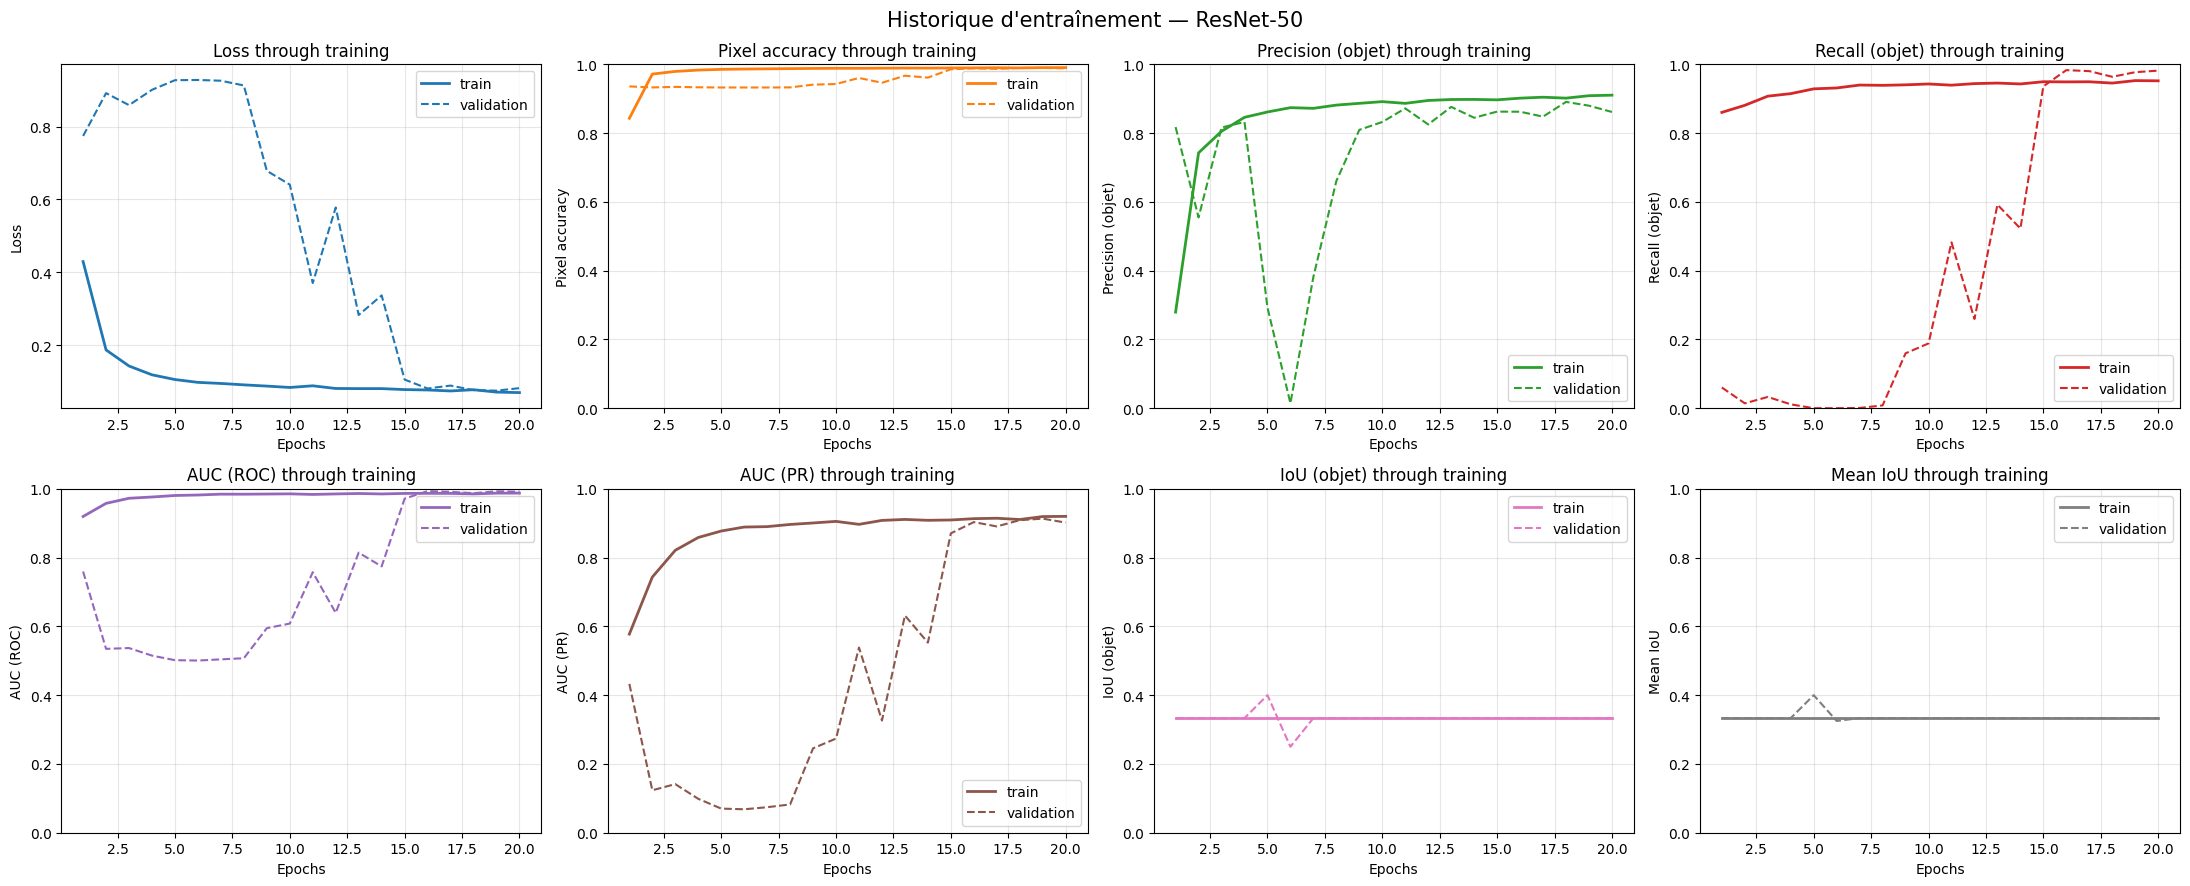

In [33]:
# Entraînement et évaluation du modèle ResNet-50
score_resnet50, history_df_resnet50 = train_and_evaluate_dl(
    get_resnet50,
    model_label="ResNet-50",
    input_key="img_pad92",
)

In [34]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

### 5.2 Versions paramétrables de ResNet

In [35]:
# --- Modele parametrable -------------------------------------------------------
# pooling       : "max"  -> Max Pooling 3x3 de pas 2 (ResNet d'origine)
#                 "conv" -> convolution 3x3 de pas 2 (reduction apprise)    [V1]
# skips_fins    : False  -> skips a 36, 72 et 143 px (modele actuel)
#                 True   -> + skips a 286 et 572 px (pleine resolution)      [V2]
def get_resnet_variant(pooling="max", skips_fins=False,
                       input_shape=(572, 572, 1), num_classes=2, name="ResNet"):
    inputs = keras.layers.Input(shape=input_shape)                     # 572

    # Encodeur ResNet-50
    x1 = keras.layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False)(inputs)
    x1 = keras.layers.BatchNormalization()(x1)
    x1 = keras.layers.Activation("relu")(x1)                           # 286

    if pooling == "max":
        x2 = keras.layers.MaxPooling2D(3, strides=2, padding="same")(x1)
    else:
        x2 = keras.layers.Conv2D(64, 3, strides=2, padding="same", use_bias=False)(x1)
        x2 = keras.layers.BatchNormalization()(x2)
        x2 = keras.layers.Activation("relu")(x2)                       # 143
    for _ in range(3):
        x2 = bottleneck_block(x2, 64)                                  # 143

    x3 = bottleneck_block(x2, 128, stride=2)                           # 72
    for _ in range(3):
        x3 = bottleneck_block(x3, 128)

    x4 = bottleneck_block(x3, 256, stride=2)                           # 36
    for _ in range(5):
        x4 = bottleneck_block(x4, 256)

    b = bottleneck_block(x4, 512, stride=2)                            # 18
    for _ in range(2):
        b = bottleneck_block(b, 512)

    # Decodeur progressif avec skip connections
    u = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)    # 36
    u = keras.layers.Concatenate()([u, x4])
    u = keras.layers.Conv2D(256, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u)    # 72
    u = keras.layers.Concatenate()([u, x3])
    u = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u)     # 144
    u = keras.layers.Resizing(143, 143)(u)                                     # 143
    u = keras.layers.Concatenate()([u, x2])
    u = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u)     # 286
    if skips_fins:
        u = keras.layers.Concatenate()([u, x1])
        u = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u)     # 572
    if skips_fins:
        x0 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
        u = keras.layers.Concatenate()([u, x0])
        u = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(u)

    # CORRECTION DU DECALAGE : on garde le centre 388x388, qui correspond
    # au masque (au lieu d'ecraser toute l'image 572 en 388 avec Resizing)
    crop = (input_shape[0] - 388) // 2                                   # 92
    u = keras.layers.Cropping2D(crop)(u)                                  # 388

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u)
    return keras.Model(inputs, outputs, name=name)

# --- Entrainement + evaluation d'une version ------------------------------------
def entrainer_et_evaluer(build_fn, model_label, batch_size=2, lr=3e-4, epochs=EPOCHS):
    score, hist_df = train_and_evaluate_dl(
        build_fn,
        model_label=model_label,
        input_key="img_pad92",
        lr=lr,
        batch_size=batch_size,
        epochs=epochs,
    )
    history_resnet_variants[model_label] = hist_df
    return score


Entraînement : V1 : ResNet-50 V1 (conv stride 2)
Epoch 1/20
73/73 [==============================] - 18s 162ms/step - loss: 0.2935 - accuracy: 0.9357 - precision: 0.5098 - recall: 0.8377 - auc: 0.9370 - auc_pr: 0.6396 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.9295 - val_accuracy: 0.9327 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.5000 - val_auc_pr: 0.0673 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500 - lr: 3.0000e-04
Epoch 2/20
73/73 [==============================] - 10s 134ms/step - loss: 0.1671 - accuracy: 0.9748 - precision: 0.7668 - recall: 0.8949 - auc: 0.9649 - auc_pr: 0.7821 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.9295 - val_accuracy: 0.9323 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.4997 - val_auc_pr: 0.0671 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.1667 - lr: 3.0000e-04
Epoch 3/20
73/73 [==============================] - 10s 137ms/step - loss: 0.1224 - accuracy: 0.9827 - precision: 0.8375 - recall: 0.9155 - au

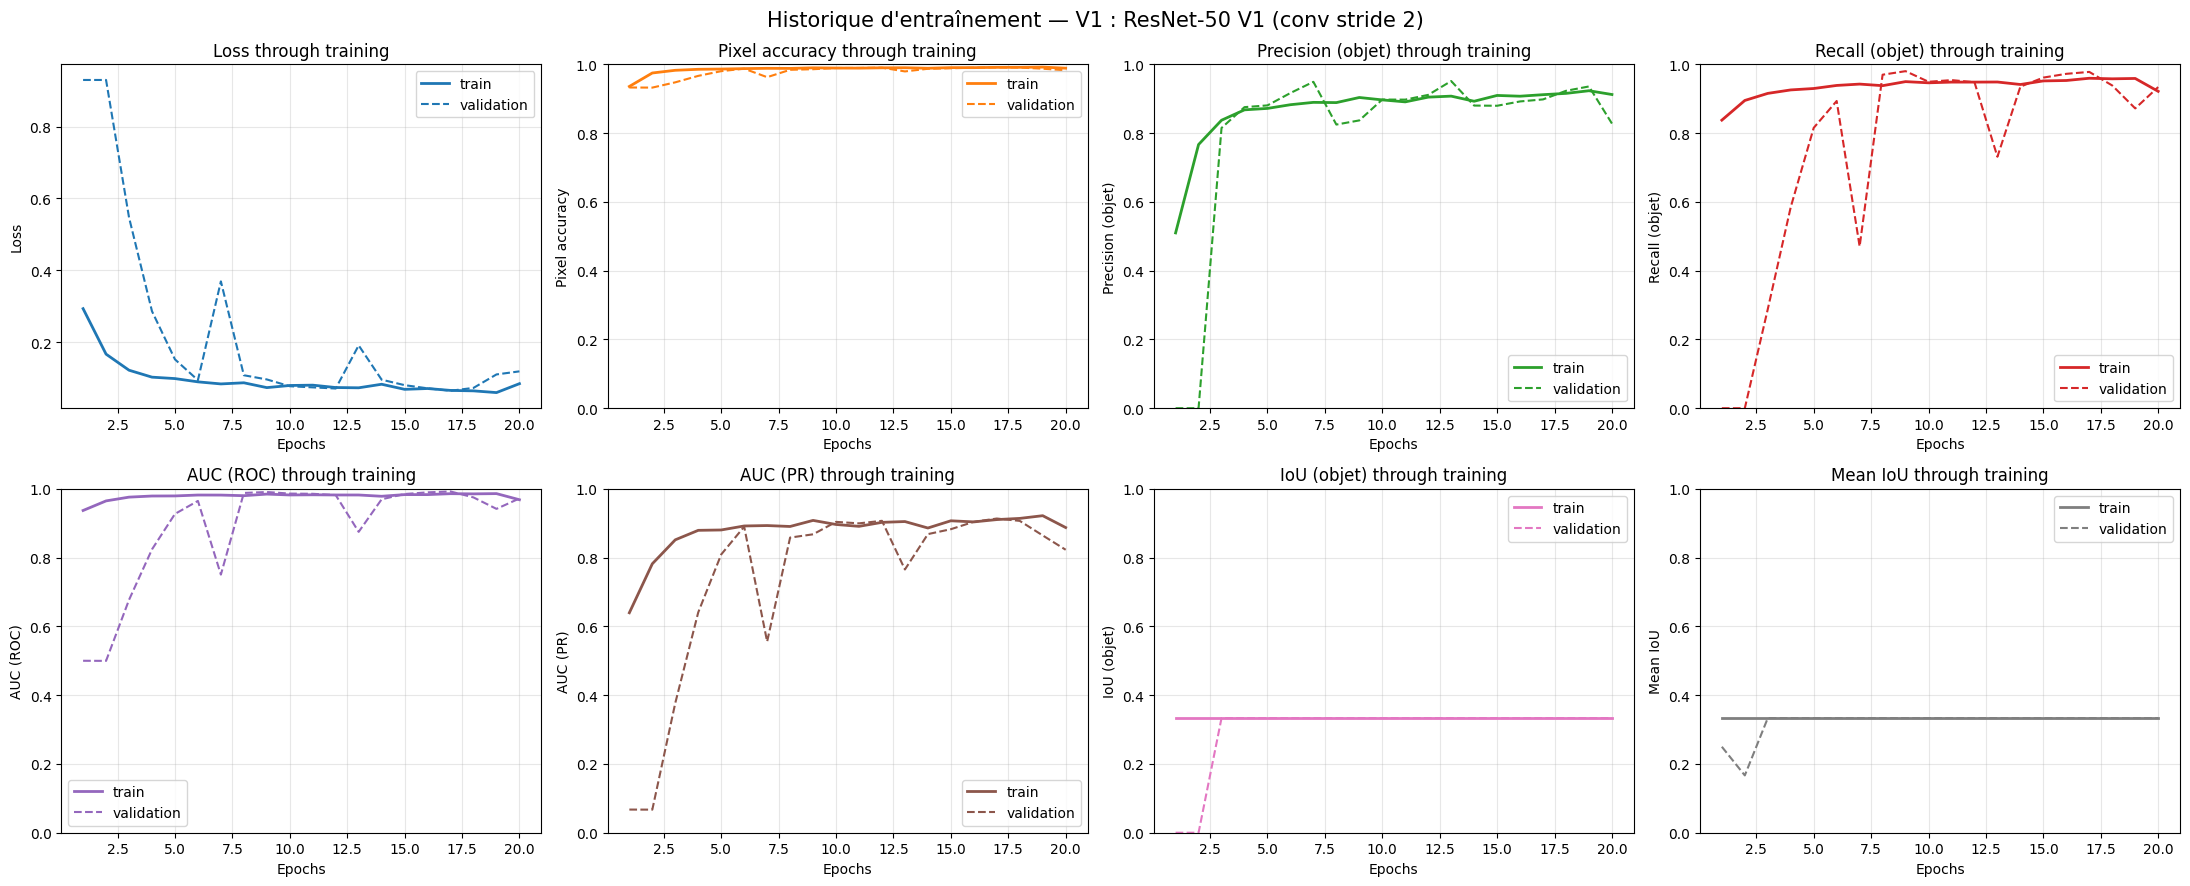


Entraînement : V2 : ResNet-50 V2 (+ skips 286 & 572)
Epoch 1/20
73/73 [==============================] - 19s 183ms/step - loss: 0.3925 - accuracy: 0.8142 - precision: 0.2500 - recall: 0.8979 - auc: 0.9321 - auc_pr: 0.6364 - iou_fg: 0.3411 - mean_iou: 0.3411 - val_loss: 0.9293 - val_accuracy: 0.9327 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.5000 - val_auc_pr: 0.0673 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500 - lr: 3.0000e-04
Epoch 2/20
73/73 [==============================] - 12s 159ms/step - loss: 0.1429 - accuracy: 0.9789 - precision: 0.8004 - recall: 0.9106 - auc: 0.9689 - auc_pr: 0.8119 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.9288 - val_accuracy: 0.9326 - val_precision: 0.0503 - val_recall: 2.3999e-05 - val_auc: 0.5006 - val_auc_pr: 0.0682 - val_iou_fg: 0.2000 - val_mean_iou: 0.2667 - lr: 3.0000e-04
Epoch 3/20
73/73 [==============================] - 12s 159ms/step - loss: 0.1121 - accuracy: 0.9843 - precision: 0.8554 - recall: 0.9186 - auc: 0

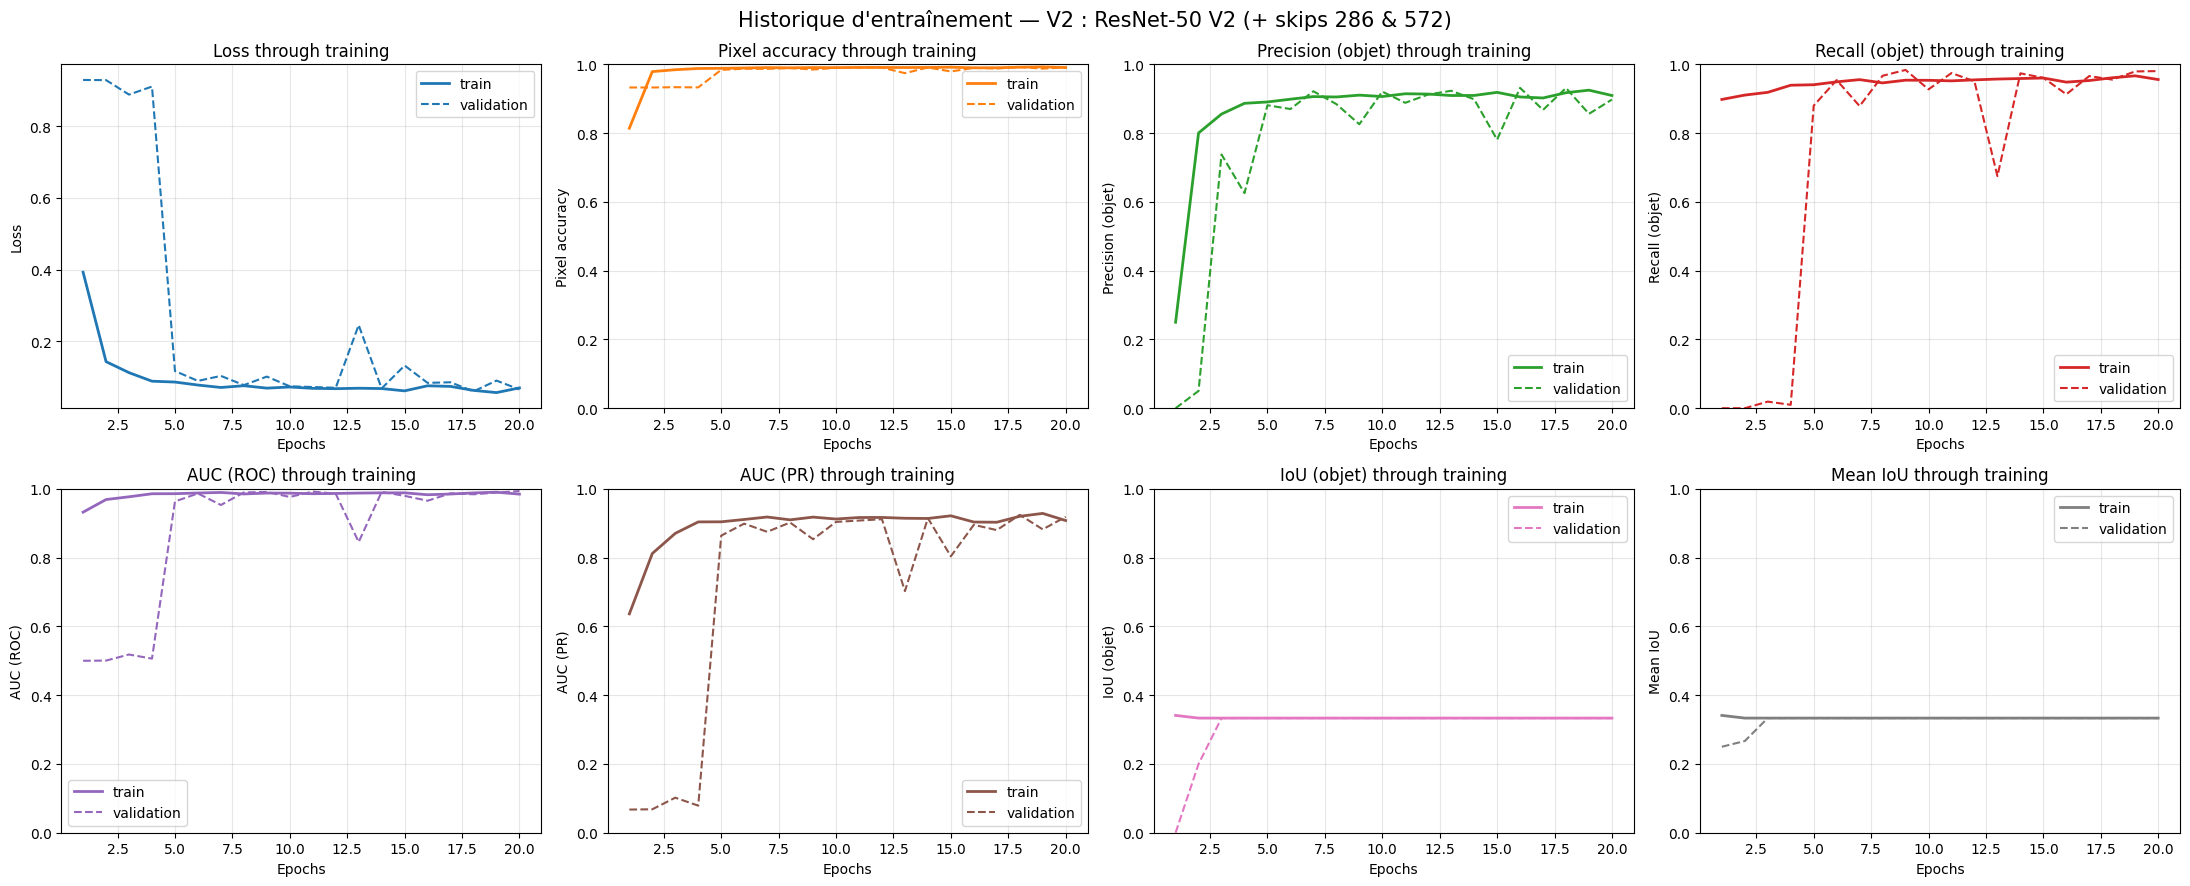

Jeu de données : PhC-C2DH-U373_train.zip


,Seuil,Accuracy,Precision (Cell),Recall (Cell),Dice / F1,IoU Cellule,Mean IoU,AUC (ROC),AUC (PR),Temps (s),Params (M)
V1 : ResNet-50 V1 (conv stride 2),0.5,0.9829,0.8291,0.9276,0.8756,0.7787,0.8802,0.9937,0.8953,205.6,29.74
V2 : ResNet-50 V2 (+ skips 286 & 572),0.5,0.991,0.8921,0.9808,0.9344,0.8768,0.9336,0.9976,0.9395,237.4,29.75


In [36]:
# --- Choix des versions a lancer -------------------------------------------
A_LANCER = ["V1", "V2"]  # ["V0", "V1", "V2"]

versions = {
    "V0": ("ResNet-50 Base (max, skips gros)",             dict(pooling="max",  skips_fins=False)),
    "V1": ("ResNet-50 V1 (conv stride 2)",                 dict(pooling="conv", skips_fins=False)),
    "V2": ("ResNet-50 V2 (+ skips 286 & 572)",             dict(pooling="max",  skips_fins=True)),
}

resultats = {}
history_resnet_variants = {}
for code in A_LANCER:
    nom, options = versions[code]
    label = f"{code} : {nom}"
    # Réduction du batch_size à 2 pour éviter l'erreur Out Of Memory (OOM) sur GPU
    resultats[label] = entrainer_et_evaluer(
        lambda opts=options, c=code: get_resnet_variant(**opts, name=c),
        model_label=label,
        batch_size=2,
    )

tableau = pd.DataFrame(resultats).T.drop(columns=["Modèle", "Jeu"], errors="ignore")
print("Jeu de données :", DATA_ZIP_PATH.name)
display(tableau)

### 5.2 Historique des variantes ResNet


In [37]:
for variant_name, history_df in history_resnet_variants.items():
    print(f"=== Historique : {variant_name} ===")
    display(history_df)

=== Historique : V1 : ResNet-50 V1 (conv stride 2) ===


,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou,lr
0,0.293546,0.935691,0.509779,0.837720,0.937033,0.639577,0.333333,0.333333,0.929502,0.932673,0.000000,0.000000,0.500000,0.067327,0.000000,0.250000,0.00030
1,0.167091,0.974822,0.766760,0.894931,0.964901,0.782064,0.333333,0.333333,0.929534,0.932327,0.000000,0.000000,0.499734,0.067106,0.000000,0.166667,0.00030
2,0.122375,0.982661,0.837452,0.915519,0.975865,0.851722,0.333333,0.333333,0.547195,0.947662,0.815014,0.287995,0.677126,0.377043,0.333333,0.333333,0.00030
3,0.103058,0.985566,0.867665,0.925594,0.979121,0.879316,0.333333,0.333333,0.286410,0.966451,0.875501,0.584862,0.823976,0.640812,0.333333,0.333333,0.00030
4,0.099100,0.986301,0.871825,0.929712,0.979367,0.880375,0.333333,0.333333,0.152506,0.980124,0.880612,0.815314,0.927053,0.809181,0.333333,0.333333,0.00030
5,0.090005,0.987559,0.882590,0.938619,0.981978,0.891998,0.333333,0.333333,0.094676,0.987350,0.916614,0.893384,0.964848,0.889998,0.333333,0.333333,0.00030
6,0.084244,0.988408,0.889398,0.942542,0.981845,0.893213,0.333333,0.333333,0.369407,0.962646,0.949109,0.470402,0.750596,0.555682,0.333333,0.333333,0.00030
7,0.087395,0.988132,0.888722,0.937932,0.980058,0.890532,0.333333,0.333333,0.108373,0.984103,0.824848,0.969820,0.988036,0.858234,0.333333,0.333333,0.00030
8,0.073980,0.989806,0.903572,0.949712,0.984683,0.908191,0.333333,0.333333,0.096730,0.985806,0.836937,0.980134,0.990770,0.867741,0.333333,0.333333,0.00030
9,0.079908,0.989193,0.896563,0.946266,0.982179,0.896343,0.333333,0.333333,0.077814,0.989291,0.897593,0.949248,0.986192,0.903919,0.333333,0.333333,0.00030


=== Historique : V2 : ResNet-50 V2 (+ skips 286 & 572) ===


,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou,lr
0,0.392524,0.814250,0.250017,0.897905,0.932126,0.636407,0.341121,0.341121,0.929255,0.932673,0.000000,0.000000,0.500000,0.067327,0.000000,0.250000,0.0003
1,0.142880,0.978880,0.800398,0.910598,0.968860,0.811939,0.333333,0.333333,0.928793,0.932644,0.050279,0.000024,0.500551,0.068154,0.200000,0.266667,0.0003
2,0.112137,0.984345,0.855395,0.918568,0.976840,0.870526,0.333333,0.333333,0.888404,0.933505,0.737717,0.019178,0.518208,0.101907,0.333333,0.333333,0.0003
3,0.088300,0.987891,0.886631,0.939251,0.985680,0.903836,0.333333,0.333333,0.910845,0.932942,0.625503,0.009941,0.506241,0.078687,0.333333,0.333333,0.0003
4,0.085887,0.988425,0.890591,0.940672,0.985889,0.904109,0.333333,0.333333,0.116623,0.983908,0.880984,0.879852,0.963310,0.863920,0.333333,0.333333,0.0003
5,0.077535,0.989446,0.898616,0.949091,0.987881,0.910889,0.333333,0.333333,0.089062,0.987318,0.870031,0.954178,0.986551,0.898791,0.333333,0.333333,0.0003
6,0.070756,0.990484,0.906193,0.955530,0.989457,0.918095,0.333333,0.333333,0.103122,0.986799,0.921692,0.878572,0.953030,0.875033,0.333333,0.333333,0.0003
7,0.075691,0.989869,0.905046,0.946017,0.985088,0.909820,0.333333,0.333333,0.077382,0.989253,0.884401,0.966740,0.989513,0.902009,0.333333,0.333333,0.0003
8,0.068906,0.990591,0.910426,0.953897,0.987693,0.917786,0.333333,0.333333,0.101132,0.984921,0.825697,0.983694,0.991015,0.853421,0.333333,0.333333,0.0003
9,0.072104,0.990379,0.906312,0.953554,0.987414,0.912196,0.333333,0.333333,0.073983,0.989727,0.920744,0.927233,0.976335,0.903819,0.333333,0.333333,0.0003


In [38]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

## 6. Réseau convolutionnel (CNN)

  Afin d'établir un point de comparaison pour évaluer l'apport du U-Net (et plus spécifiquement, de son architecture particulière), nous nous proposons d'implémenter un réseau de neurones convolutif traditionnel adoptant une architecture séquentielle sans skip connections.

  La première partie du réseau, l'encodeur, partage la même dynamique d'extraction de caractéristiques que le U-Net. Elle est constituée de blocs successifs comprenant des convolutions de taille 3 × 3 suivies d'activations ReLU et d'opérations de max pooling 2 × 2.

  Le réseau transite ensuite par un goulot d'étranglement avant d'entamer la phase de reconstruction avec le décodeur. Ce dernier augmente la résolution à chaque étage via des up-convolutions de taille 2 × 2, suivies de convolutions classiques 3 × 3. Contrairement au U-Net, cette étape de remontée ne bénéficie d'aucune concaténation avec les cartes de l'encodeur, ainsi le décodeur doit tenter de reconstituer la localisation spatiale exacte des anomalies uniquement à partir du résumé hautement compressé issu du goulot d'étranglement.

  Enfin, une convolution finale 1 × 1 est appliquée pour attribuer une classe à chaque pixel et générer la carte de segmentation. L'objectif principal de cette implémentation est de mesurer les limites d'une architecture purement séquentielle dans la délimitation précise des zones suspectes, en observant particulièrement l'impact de l'absence de raccourcis spatiaux sur notre métrique de priorité, le recall.

In [39]:
# Définition des blocs de convolution et de sur-échantillonnage
def conv_block_basic(x: tf.Tensor, filters: int) -> tf.Tensor:
    """Deux couches de convolution 3x3 suivies d'une activation ReLU (sans padding)."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    return x


def up_block_basic(x: tf.Tensor, filters: int) -> tf.Tensor:
    """Sur-échantillonnage 2x2 séquentiel direct (sans skip connections) puis conv_block_basic."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2)(x)
    return conv_block_basic(x, filters)


# Définition du modèle CNN séquentiel de référence
def get_basic_cnn(input_shape=(572, 572, 1), num_classes=2) -> keras.Model:
    """CNN de base sans connexions résiduelles utilisé pour mesurer l'apport des skip connections."""
    inputs = keras.Input(input_shape)

    # Encodeur
    x1 = conv_block_basic(inputs, 64)
    x2 = conv_block_basic(keras.layers.MaxPooling2D(2)(x1), 128)
    x3 = conv_block_basic(keras.layers.MaxPooling2D(2)(x2), 256)
    x4 = conv_block_basic(keras.layers.MaxPooling2D(2)(x3), 512)

    # Bottleneck
    b = conv_block_basic(keras.layers.MaxPooling2D(2)(x4), 1024)

    # Décodeur séquentiel
    d4 = up_block_basic(b, 512)
    d3 = up_block_basic(d4, 256)
    d2 = up_block_basic(d3, 128)
    d1 = up_block_basic(d2, 64)

    # Couche de classification pixel par pixel
    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)

    return keras.Model(inputs, outputs, name="basic_cnn")


basic_cnn = get_basic_cnn()
basic_cnn.summary()

Model: "basic_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 572, 572, 1)]     0         
                                                                 
 conv2d (Conv2D)             (None, 570, 570, 64)      640       
                                                                 
 conv2d_1 (Conv2D)           (None, 568, 568, 64)      36928     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 284, 284, 64)     0         
 )                                                               
                                                                 
 conv2d_2 (Conv2D)           (None, 282, 282, 128)     73856     
                                                                 
 conv2d_3 (Conv2D)           (None, 280, 280, 128)     147584    
                                                         


Entraînement : CNN basique
Epoch 1/20
36/36 [==============================] - 15s 366ms/step - loss: 0.6801 - accuracy: 0.7193 - precision: 0.1551 - recall: 0.7226 - auc: 0.7546 - auc_pr: 0.2811 - iou_fg: 0.3516 - mean_iou: 0.3516 - val_loss: 0.3738 - val_accuracy: 0.9489 - val_precision: 0.6247 - val_recall: 0.6029 - val_auc: 0.7896 - val_auc_pr: 0.4368 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 2/20
36/36 [==============================] - 12s 338ms/step - loss: 0.2921 - accuracy: 0.9568 - precision: 0.6537 - recall: 0.7489 - auc: 0.8626 - auc_pr: 0.5387 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.2410 - val_accuracy: 0.9654 - val_precision: 0.7274 - val_recall: 0.7776 - val_auc: 0.8812 - val_auc_pr: 0.6120 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333 - lr: 3.0000e-04
Epoch 3/20
36/36 [==============================] - 12s 336ms/step - loss: 0.1987 - accuracy: 0.9715 - precision: 0.7584 - recall: 0.8343 - auc: 0.9131 - auc_pr: 0.6876 - iou_fg: 0.3333 - 

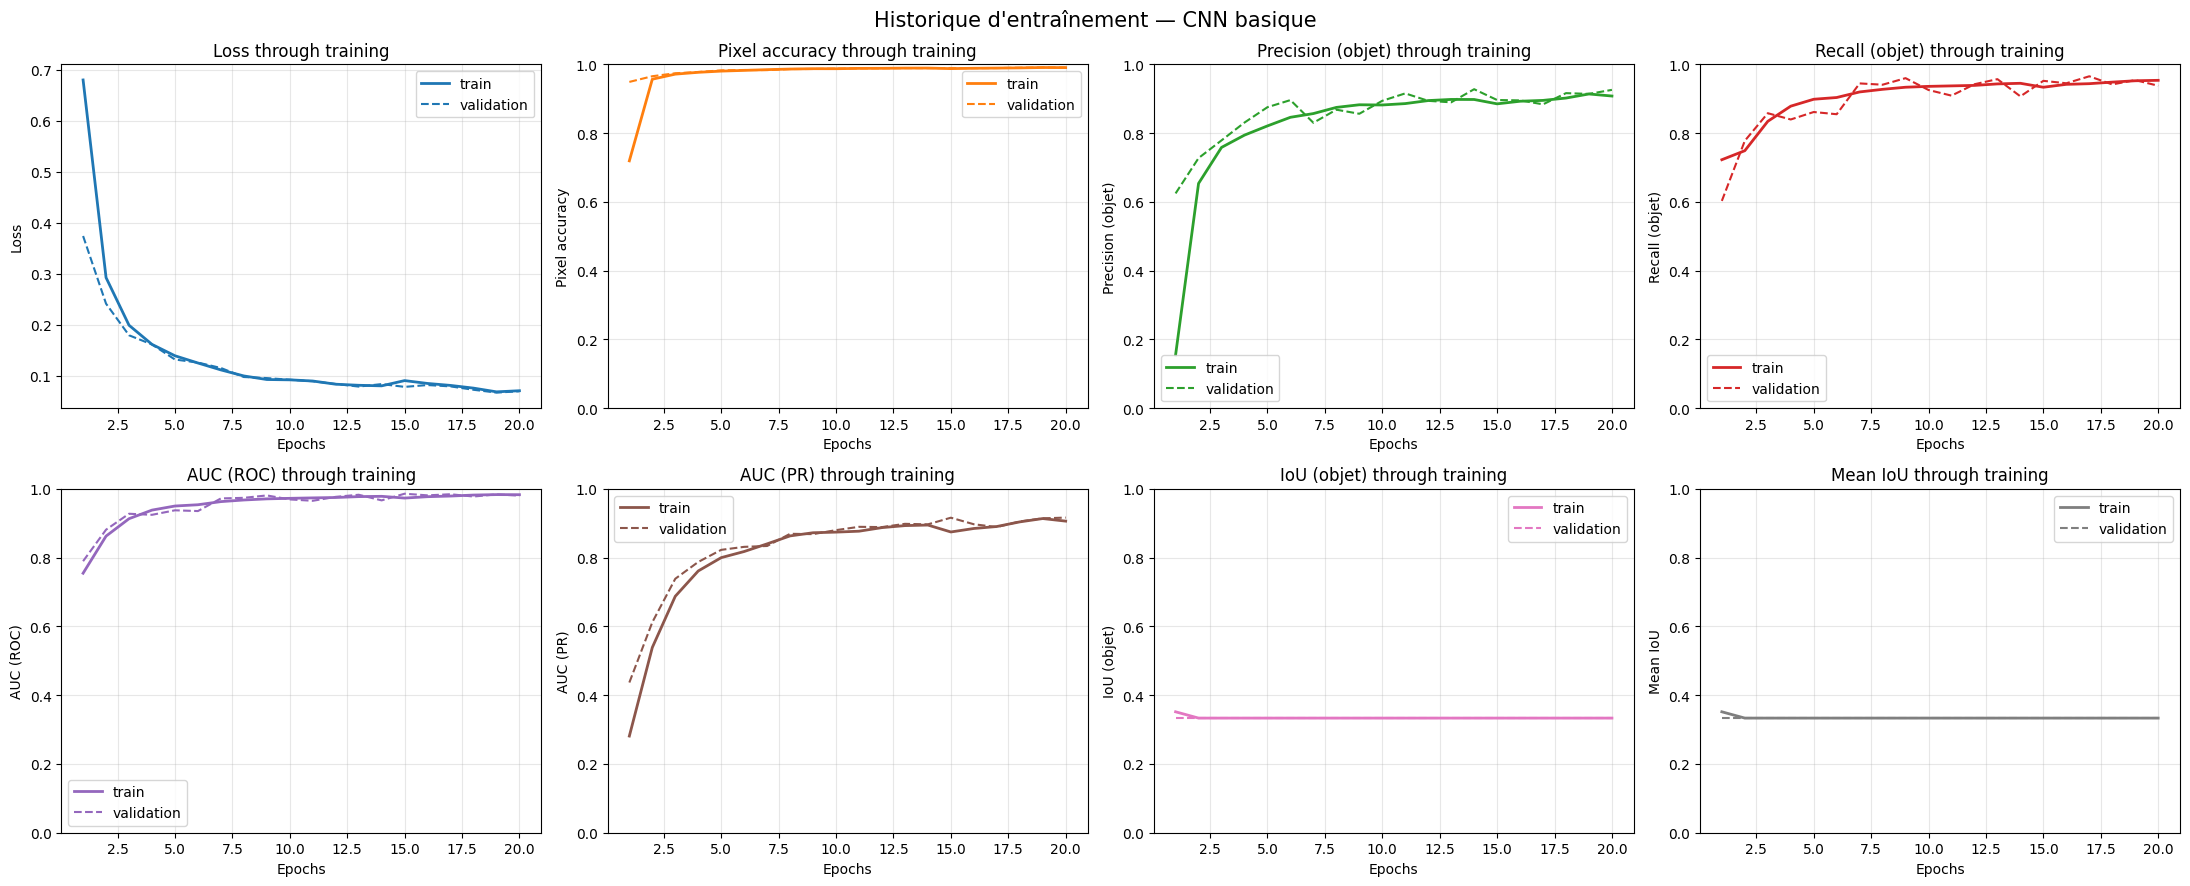

In [40]:
# Entraînement et évaluation du modèle CNN basique
score_basic_cnn, history_df_basic_cnn = train_and_evaluate_dl(
    get_basic_cnn,
    model_label="CNN basique",
    input_key="img_pad92",
)

In [41]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

## 7. DeepLabV3+
méthode encoder-decoder différente de Unet utilisant convolution dilatée

In [57]:
# Définition du bloc de convolution élémentaire (séparable ou classique)
def convolution_block(block_input: tf.Tensor, num_filters: int = 256, kernel_size: int = 3, dilation_rate: int = 1, use_bias: bool = False) -> tf.Tensor:
    """Convolution séparable (si noyau 3x3) ou classique suivie d'une BatchNormalization et ReLU."""
    if kernel_size == 3:
        x = keras.layers.SeparableConv2D(
            filters=num_filters,
            kernel_size=kernel_size,
            dilation_rate=dilation_rate,
            padding="same",
            use_bias=use_bias,
            depthwise_initializer=keras.initializers.HeNormal(),
            pointwise_initializer=keras.initializers.HeNormal(),
        )(block_input)
    else:
        x = keras.layers.Conv2D(
            filters=num_filters,
            kernel_size=kernel_size,
            dilation_rate=dilation_rate,
            padding="same",
            use_bias=use_bias,
            kernel_initializer=keras.initializers.HeNormal(),
        )(block_input)

    x = keras.layers.BatchNormalization()(x)
    return keras.activations.relu(x)


# Définition du module ASPP (Atrous Spatial Pyramid Pooling)
def dilated_spatial_pyramid_pooling(dspp_input: tf.Tensor) -> tf.Tensor:
    """Module ASPP combinant un pooling global et plusieurs convolutions dilatées (taux 1, 6, 12, 18)."""
    dims = dspp_input.shape

    # Branche 1 : Pooling moyen global et sur-échantillonnage bilinéaire
    x = keras.layers.AveragePooling2D(pool_size=(dims[1], dims[2]))(dspp_input)
    x = convolution_block(x, kernel_size=1, use_bias=True)
    out_pool = keras.layers.UpSampling2D(
        size=(dims[1] // x.shape[1], dims[2] // x.shape[2]),
        interpolation="bilinear",
    )(x)

    # Branches 2 à 5 : Convolutions parallèles à différents taux de dilatation
    out_1 = convolution_block(dspp_input, kernel_size=1, dilation_rate=1)
    out_6 = convolution_block(dspp_input, kernel_size=3, dilation_rate=6)
    out_12 = convolution_block(dspp_input, kernel_size=3, dilation_rate=12)
    out_18 = convolution_block(dspp_input, kernel_size=3, dilation_rate=18)

    # Fusion multi-échelle et projection 1x1
    x_concatenated = keras.layers.Concatenate(axis=-1)([out_pool, out_1, out_6, out_12, out_18])
    return convolution_block(x_concatenated, kernel_size=1)


# Définition du modèle DeepLabV3+
def get_deeplabv3_plus(image_size: int = 572, num_classes: int = 2) -> keras.Model:
    """Modèle DeepLabV3+ combinant un encodeur ResNet-50, un module ASPP et un décodeur à double échelle."""
    model_input = keras.Input(shape=(image_size, image_size, 1))

    # Encodeur (backbone ResNet-50) et extraction des caractéristiques profondes
    resnet_backbone = keras.applications.ResNet50(
        weights=None, include_top=False, input_tensor=model_input
    )
    x = resnet_backbone.get_layer("conv4_block6_2_relu").output
    x_aspp = dilated_spatial_pyramid_pooling(x)

    # Décodeur : sur-échantillonnage des caractéristiques ASPP (facteur 4)
    input_a = keras.layers.UpSampling2D(
        size=(image_size // 4 // x_aspp.shape[1], image_size // 4 // x_aspp.shape[2]),
        interpolation="bilinear",
    )(x_aspp)

    # Extraction des caractéristiques bas niveau (skip connection) et alignement spatial
    input_b = resnet_backbone.get_layer("conv2_block3_2_relu").output
    input_b_conv = convolution_block(input_b, num_filters=48, kernel_size=1)
    input_a_resized = keras.layers.Resizing(input_b_conv.shape[1], input_b_conv.shape[2])(input_a)

    # Fusion des flux haut et bas niveau puis raffinement par convolution
    x_decoded = keras.layers.Concatenate(axis=-1)([input_a_resized, input_b_conv])
    x_decoded = convolution_block(x_decoded)
    x_decoded = convolution_block(x_decoded)

    # Remontée à la résolution d'entrée, recadrage (572x572 -> 388x388) et prédiction finale
    x_upsampled = keras.layers.UpSampling2D(
        size=(image_size // x_decoded.shape[1], image_size // x_decoded.shape[2]),
        interpolation="bilinear",
    )(x_decoded)

    x_resized = keras.layers.Resizing(572, 572)(x_upsampled)
    x_cropped = keras.layers.Cropping2D(((92, 92), (92, 92)))(x_resized)
    model_output = keras.layers.Conv2D(num_classes, kernel_size=(1, 1), padding="same", activation="softmax")(x_cropped)

    return keras.Model(inputs=model_input, outputs=model_output)


deeplabv3_plus = get_deeplabv3_plus(image_size=572, num_classes=2)
deeplabv3_plus.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 578, 578, 1)  0           ['input_2[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 286, 286, 64  3200        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                            

In [ ]:
# Entraînement et évaluation du modèle DeepLabV3+
# Entraînement DeepLabV3+ avec des lots réduits pour éviter l'OOM GPU
# La mémoire GPU est également configurée en croissance dynamique
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print(f"Configuration mémoire GPU ignorée : {exc}")

# Mixed precision : utile sur GPU compatibles, notamment NVIDIA
keras.mixed_precision.set_global_policy("mixed_float16")

score_deeplabv3_plus, history_df_deeplabv3_plus = train_and_evaluate_dl(
    lambda: get_deeplabv3_plus(image_size=572, num_classes=2),
    model_label="DeepLabV3+",
    input_key="img_pad92",
    batch_size=1,
)


Entraînement : DeepLabV3+
Epoch 1/20
36/36 [==============================] - ETA: 0s - loss: 0.3717 - accuracy: 0.9224 - precision: 0.4572 - recall: 0.8836 - auc: 0.9545 - auc_pr: 0.6177 - iou_fg: 0.3333 - mean_iou: 0.3333

ResourceExhaustedError: Graph execution error:

Detected at node 'model/up_sampling2d_2/resize/ResizeBilinear' defined at (most recent call last):
    File "C:\Users\Antonin\AppData\Local\Python\pythoncore-3.10-64\lib\runpy.py", line 196, in _run_module_as_main
      return _run_code(code, main_globals, None,
    File "C:\Users\Antonin\AppData\Local\Python\pythoncore-3.10-64\lib\runpy.py", line 86, in _run_code
      exec(code, run_globals)
    File "c:\Users\Antonin\Studies\Project\UNet_&_CNN\.venv\lib\site-packages\ipykernel_launcher.py", line 18, in <module>
      app.launch_new_instance()
    File "c:\Users\Antonin\Studies\Project\UNet_&_CNN\.venv\lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
      app.start()
    File "c:\Users\Antonin\Studies\Project\UNet_&_CNN\.venv\lib\site-packages\ipykernel\kernelapp.py", line 739, in start
      self.io_loop.start()
    File "c:\Users\Antonin\Studies\Project\UNet_&_CNN\.venv\lib\site-packages\tornado\platf

In [ ]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory()

## 8. Méthodes de machine learning

### 8.1 Création des caractéristiques

In [42]:
def extract_pixel_features(img_std):
    """Extrait 17 descripteurs multi-échelles par pixel (intensité, flou, gradient Sobel, Laplacien, écart-type local)."""
    feats = [img_std]
    for sigma in [1.0, 2.0, 4.0, 8.0]:
        blur = ndi.gaussian_filter(img_std, sigma=sigma)
        grad = np.hypot(ndi.sobel(blur, axis=1), ndi.sobel(blur, axis=0))
        lap = ndi.gaussian_laplace(img_std, sigma=sigma)
        win = int(2 * sigma + 1)
        m1 = ndi.uniform_filter(img_std, size=win)
        m2 = ndi.uniform_filter(img_std ** 2, size=win)
        feats.extend([blur, grad, lap, np.sqrt(np.maximum(m2 - m1 ** 2, 0.0))])
    stacked = np.stack(feats, axis=-1)
    return stacked.reshape(-1, stacked.shape[-1]).astype(np.float32)


def build_ml_dataset(items, max_pixels=None):
    """Construit les matrices tabulaires (X, y) alignées sur mask_raw avec échantillonnage pondéré sur Train."""
    rng = np.random.default_rng(SEED)
    X_list, y_list = [], []
    for it in items:
        X_img = extract_pixel_features(it["img"])
        y_img = it["mask_raw"].ravel()
        if max_pixels and max_pixels < len(y_img):
            probs = it["weight"].ravel() / np.sum(it["weight"])
            idx = rng.choice(len(y_img), size=max_pixels, replace=False, p=probs)
            X_img, y_img = X_img[idx], y_img[idx]
        X_list.append(X_img)
        y_list.append(y_img)
    return np.vstack(X_list), np.concatenate(y_list)

In [43]:
t0 = time.perf_counter()
X_train_ml, y_train_ml = build_ml_dataset(train_items, max_pixels=6000)
X_val_ml, y_val_ml = build_ml_dataset(val_items)
X_test_ml, y_test_ml = build_ml_dataset(test_items)
t_feat_train = time.perf_counter() - t0

print(f"ML Shapes -> Train: {X_train_ml.shape} | Val: {X_val_ml.shape} | Test: {X_test_ml.shape} ({t_feat_train:.1f}s)")

ML Shapes -> Train: (882000, 17) | Val: (5570128, 17) | Test: (6925024, 17) (17.5s)


In [44]:
# Évaluation des modèles de ML via les fonctions communes find_best_threshold et evaluate_predictions
def evaluate_ml_model(clf, model_label, train_time_s, params_m=np.nan):
    """Ajuste le seuil sur Validation (F1/Dice) puis évalue le modèle ML sur Test sur mask_raw."""
    val_probs = clf.predict_proba(X_val_ml)[:, 1]
    best_th = 0.5
    val_scores = evaluate_predictions(y_val_ml, val_probs, threshold=best_th, model_name=model_label, split_name="Validation")

    test_probs = clf.predict_proba(X_test_ml)[:, 1]
    test_scores = evaluate_predictions(y_test_ml, test_probs, threshold=best_th, model_name=model_label, split_name="Test")
    test_scores["Temps (s)"] = round(train_time_s, 1)
    test_scores["Params (M)"] = params_m

    all_model_scores[model_label] = {k: v for k, v in test_scores.items() if k != "Jeu"}

    df_res = pd.DataFrame([val_scores, test_scores]).set_index(["Modèle", "Jeu"])
    display(df_res.style.format("{:.4f}", subset=[c for c in df_res.columns if c not in ("Seuil", "Params (M)")]))
    return test_scores

### 8.2 Random Forest

In [45]:
rf_clf = RandomForestClassifier(
    n_estimators=150,
    max_depth=16,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=SEED,
)
t0 = time.perf_counter()
rf_clf.fit(X_train_ml, y_train_ml)
rf_time = time.perf_counter() - t0

score_rf = evaluate_ml_model(rf_clf, model_label="Random Forest", train_time_s=rf_time)

In [46]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory([rf_clf])

### 8.3 XGBoost

In [47]:
xgb_clf = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="logloss",
    n_jobs=-1,
    random_state=SEED,
)
t0 = time.perf_counter()
xgb_clf.fit(X_train_ml, y_train_ml)
xgb_time = time.perf_counter() - t0

score_xgb = evaluate_ml_model(xgb_clf, model_label="XGBoost", train_time_s=xgb_time)

In [48]:
# Clear mémoire pour sauvegarder de la RAM
cleanup_memory([xgb_clf, X_train_ml, y_train_ml, X_val_ml, y_val_ml, X_test_ml, y_test_ml])

## 9. Comparaison et analyse

Les résultats enregistrés montrent des prédictions presque uniquement d'arrière-plan pour le U-Net simplifié et ResNet-50 (precision et recall proches de zéro), ainsi qu'un recall très faible pour le U-Net ASPP. Dans ces cas, Dice et IoU sont proches de zéro : ces scores signalent un échec de segmentation et ne permettent pas de conclure à une comparaison utile des architectures. L'architecture ASPP et la tête de sortie ResNet-50 ayant été corrigées, ces modèles doivent être réentraînés et réévalués avant d'interpréter le tableau ; les sorties sauvegardées précédemment ne reflètent pas ces corrections.

Le protocole d'entraînement n'est pas identique entre familles : les réseaux convolutifs sont entraînés sans augmentation de données ni carte de poids, tandis que les méthodes ML utilisent des images standardisées et un échantillonnage de pixels pondéré par les poids. Les paramètres LR, MOMENTUM, EPOCHS et STEPS_PER_EPOCH, ainsi que rotation, gray_value_variation et augment, sont définis mais ne sont pas utilisés par l'entraînement actuel. Il faut donc nuancer la comparaison ; les losses ne sont pas directement comparables entre méthodes.

Enfin, le découpage aléatoire est effectué au niveau des frames, après réunion des séquences 01 et 02. Des frames consécutives et très similaires peuvent ainsi se retrouver dans les ensembles d'entraînement, validation et test, ce qui peut gonfler les scores. Un découpage par séquence ou par blocs temporels serait plus rigoureux ; les résultats actuels doivent être interprétés en tenant compte de cette limite.

In [ ]:
df_final = pd.DataFrame(list(all_model_scores.values())).sort_values(by="IoU Cellule", ascending=False).reset_index(drop=True)
display(
    df_final.style
    .format("{:.4f}", subset=[c for c in df_final.columns if c not in ("Modèle", "Seuil", "Temps (s)", "Params (M)")])
    .format("{:.3f}", subset=["Seuil"])
    .format("{:.1f}", subset=["Temps (s)"], na_rep="-")
    .format("{:.2f}", subset=["Params (M)"], na_rep="-")
    .highlight_max(subset=["Accuracy", "Precision (Cell)", "Recall (Cell)", "Dice / F1", "IoU Cellule", "Mean IoU", "AUC (ROC)", "AUC (PR)"], color="lightgrey")
)

fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(len(df_final))
width = 0.36

ax.bar(x_pos - width / 2, df_final["IoU Cellule"], width, label="IoU Cellule (classe 1)", color="#2b5c8f")
ax.bar(x_pos + width / 2, df_final["Dice / F1"], width, label="Dice / F1", color="#5da5da")

ax.set_xticks(x_pos)
ax.set_xticklabels(df_final["Modèle"], rotation=25, ha="right")
ax.set_ylabel("Score sur le jeu de test (20%)")
ax.set_ylim(0, 1.05)
ax.set_title(f"Comparaison finale des modèles de segmentation cellulaire ({DATA_ZIP_PATH.stem})")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()